<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Pregunta 2: desafío Kaggle
Integrantes:
- Nelson Fuentes
- Eduardo Pérez
- Eduardo Sandoval
- Ricardo Pastén

Se predice si una licitación quedará desierta con información disponible al publicarla. La pauta adjunta confirma que la métrica es F1 para la clase desierta.


El trabajo conserva seis partes: datos y protocolo, regresión logística, comparación de modelos, elección del umbral, árboles y ensambles, y decisión final.

Esta revisión agrega dos mejoras sobre la versión anterior: (1) **tasas históricas de desierta** por comprador, categoría, comprador × categoría y comprador × título (relicitaciones), calculadas solo con etiquetas ya maduras y suavizadas; y (2) un **modelo de boosting de gradiente** que se compara con las regresiones logísticas y los árboles bajo el mismo protocolo temporal. También se audita el plazo de postulación y la fecha de publicación antes de modelar.

Se conserva lo anterior: texto con unigramas y vocabulario acotado, selección en tres ventanas temporales y la comparación del **monto estimado en CLP**, sin mezclar monedas. F1 sigue siendo la métrica de la tarea; Average Precision (AP) permite seleccionar modelos antes de elegir el umbral.

Se mantiene la corrección del protocolo anterior: una publicación anterior al corte puede seguir abierta y su etiqueta no estaría disponible. El entrenamiento, las tasas históricas y las decisiones usan solo casos cuyo cierre más un margen de 30 días precede al corte. Ese margen es una aproximación conservadora, porque no tenemos la fecha real de publicación del desenlace.

## Librerías


In [1]:
import hashlib
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.special import expit
from scipy.sparse import csr_matrix, hstack

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "y_desierta"
plt.rcParams["figure.figsize"] = (12, 5)
sns.set_palette("deep")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

NumPy 1.26.2 | pandas 2.3.3 | scikit-learn 1.9.1


# 1. Datos y protocolo

Se predice `y_desierta`: **1** significa que la licitación quedó desierta y **0**, que no quedó desierta. Primero se revisan los archivos, los datos faltantes y la distribución de ambas clases. Después se separan los datos por fecha y se fija cuánto pesa cada tipo de error.


### Carga de datos

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
assert list(pd.read_csv("sample_submission.csv", nrows=0).columns) == ["id", TARGET]
# Solo se leen los identificadores de la plantilla; sus etiquetas de ejemplo se ignoran.
sample_submission_df = pd.read_csv("sample_submission.csv", usecols=["id"])

### Inspección e integridad

In [3]:
for nombre, df in {"train": train_df, "test": test_df}.items():
    print(nombre, df.shape)
    display(df.head(3))

train (152553, 24)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion,y_desierta
0,248328745624,2024-03-25T15:32:20Z,LP04-2024 AV. UNO SUR AYSEN,"CONSTRUCCIÓN CALZADA H.C.V. AVENIDA UNO SUR, P...",NaN,NaN,open,Licitación Pública MOP (O1),1,1.0,...,2024-04-12T10:00:00Z,17.769,False,11.0,SERVICIO DE VIVIENDA Y URBANIZACION XI REGION ...,CL-MP-1653,618230007,Región Aysén del General Carlos Ibáñez del Campo,RAMON FREIRE Nº 5,0
1,760555527084,2024-03-21T14:29:28Z,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...,licitar las obras de infraestructura de mejora...,NaN,NaN,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),1,1.0,...,2024-04-15T20:00:00Z,25.230,False,21.0,CORPORACION MUNICIPAL DE EDUCACION Y SALUD DE ...,CL-MP-1274286,709255002,Región Metropolitana de Santiago,O'HIGGINS 840,1
2,224829110991,2024-01-26T12:37:41Z,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA USUA...,3500000.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),55,12150.0,...,2024-02-01T13:24:00Z,6.032,False,3.0,I MUNICIPALIDAD DE CHANCO | I MUNICIPALIDAD DE...,CL-MP-4391,69120300K,Región del Maule,Ignacio Carrera Pinto Nº 31,0


test (21829, 23)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_inicio,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion
0,47254358932,2025-03-12T15:46:53Z,SC 36914 (CM) ADQUISICIÓN DE MOBILIARIO PARA C...,ADQUISICIÓN DE MOBILIARIO PARA CLÍNICA JURÍDIC...,4999999.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),3,24.0,...,2025-03-12T15:46:47Z,2025-03-20T15:30:00Z,7.988,False,2.0,UNIVERSIDAD DE PLAYA ANCHA DE CIENCIAS DE LA E...,CL-MP-5385,707547006,Región Metropolitana de Santiago,Av. A Bello 2687
1,295671198916,2025-01-06T17:34:25Z,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,20000000.0,CLP,open,Licitación Pública Entre 100 y 1000 UTM (LE),45,123593.0,...,2025-01-06T17:34:19Z,2025-01-16T19:53:00Z,10.096,False,3.0,I MUNICIPALIDAD DE MAULE | I MUNICIPALIDAD DE ...,CL-MP-5605,691109003,Región del Maule,Balmaceda N° 350
2,214756376398,2025-02-26T12:48:51Z,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,NaN,NaN,open,Licitación Pública Entre 100 y 1000 UTM (LE),1,19000.0,...,2025-02-26T12:48:41Z,2025-03-03T15:00:00Z,5.091,False,2.0,I MUNICIPALIDAD DE QUILICURA | DEPARTAMENTO CO...,CL-MP-3475,690713004,Región Metropolitana de Santiago,NaN


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria         152528 non-null  object 
 11  pub_categoria_id      152528 non-null  float64
 12  pub_n_categorias      152553 non-null  int64  
 13  pub_inicio            152553 non-null  object 
 14  pub_cierre            152526 non-null  object 
 15  

In [5]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21829 entries, 0 to 21828
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    21829 non-null  int64  
 1   pub_fecha             21829 non-null  object 
 2   pub_titulo            21829 non-null  object 
 3   pub_descripcion       21829 non-null  object 
 4   pub_monto_estimado    10230 non-null  float64
 5   pub_moneda            10226 non-null  object 
 6   pub_metodo            21734 non-null  object 
 7   pub_modalidad         21829 non-null  object 
 8   pub_n_items           21829 non-null  int64  
 9   pub_cantidad_total    21829 non-null  float64
 10  pub_categoria         21828 non-null  object 
 11  pub_categoria_id      21828 non-null  float64
 12  pub_n_categorias      21829 non-null  int64  
 13  pub_inicio            21829 non-null  object 
 14  pub_cierre            21823 non-null  object 
 15  pub_dias_postulacio

In [6]:
assert TARGET in train_df and TARGET not in test_df
assert train_df[TARGET].notna().all()
assert set(train_df[TARGET].unique()) == {0, 1}
assert set(train_df.columns) - {TARGET} == set(test_df.columns)
assert len(train_df) == 152553 and len(test_df) == 21829
for df in (train_df, test_df, sample_submission_df):
    assert df["id"].notna().all() and df["id"].is_unique
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert sample_submission_df["id"].equals(test_df["id"])
assert TARGET not in sample_submission_df

### Distribución de la clase objetivo

In [7]:
frecuencias = train_df[TARGET].value_counts().sort_index()
pd.DataFrame({"registros": frecuencias, "porcentaje": 100 * frecuencias / len(train_df)})

,registros,porcentaje
y_desierta,,
0,122006,79.976139
1,30547,20.023861


Cerca del 20% de las licitaciones de 2024 quedaron desiertas. Predecir siempre «no desierta» tendría alta exactitud, pero no detectaría ninguna desierta. Esta distribución global es descriptiva: los pesos de los errores se calculan solo con las etiquetas admisibles del primer entrenamiento. Ninguna decisión usa etiquetas de 2025.

### Valores nulos

In [8]:
nulos = train_df.isna().sum()
pd.DataFrame({"nulos": nulos, "porcentaje": 100 * nulos / len(train_df)})

,nulos,porcentaje
id,0,0.000000
pub_fecha,0,0.000000
pub_titulo,9,0.005900
pub_descripcion,9,0.005900
pub_monto_estimado,67266,44.093528
pub_moneda,67302,44.117127
pub_metodo,68,0.044575
pub_modalidad,0,0.000000
pub_n_items,0,0.000000
pub_cantidad_total,0,0.000000


`pub_monto_estimado` y `pub_moneda` tienen cerca del 44% de valores nulos.

### Ausencia de monto y moneda

In [9]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["pub_moneda"].isna(),
    rownames=["Monto nulo"],
    colnames=["Moneda nula"]
)

Moneda nula,False,True
Monto nulo,,
False,85251,36
True,0,67266


El monto tiene muchos faltantes. Se conservan los indicadores de ausencia y la moneda. Como variable económica se propone `log_monto_clp = log(1 + monto)` **solo para montos positivos en CLP**. Para otras monedas, montos inválidos o faltantes queda como NaN. Así no se mezclan pesos, dólares y UF ni se requiere información externa. Su aporte se comprueba mediante una ablación temporal antes de evaluar D.

### Ausencia de monto por categoría

In [10]:
resumen_categoria_montos = train_df.groupby("pub_categoria", dropna=False)["pub_monto_estimado"].agg(
    total="size",
    porcentaje_nulos=lambda valores: 100 * valores.isna().mean()
)
resumen_categoria_montos.query("total >= 30").sort_values(
    ["porcentaje_nulos", "total"], ascending=[False, False]
).head(20)

,total,porcentaje_nulos
pub_categoria,,
Obras MINVU / Obras MINVU / Grupo 2 / 3°,190,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 2°,105,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 1°,85,100.000000
Obras / Obras Mayores / Obra Civil / 2da,77,100.000000
Consultoria / Consultoria / Inspecciones / 1a S,71,100.000000
Obras /Obras Menores/Obra Menor / A,48,100.000000
Consultoria / Consultoria / Ingeniería Civil / 1a S,47,100.000000
Consultoria / Consultoria / Inspecciones / 2da,41,100.000000
Obras / Obras Mayores / Obra Civil / 3,39,100.000000


Algunas categorías tienen todos sus montos ausentes. Se muestran las de al menos 30 registros para reducir el peso de grupos pequeños. Esta exploración no usa el objetivo.

### Fechas y particiones temporales

In [11]:
datos = train_df.copy()
datos["pub_fecha"] = pd.to_datetime(datos["pub_fecha"], errors="raise", utc=True)
fechas_test = pd.to_datetime(test_df["pub_fecha"], errors="raise", utc=True)
assert datos["pub_fecha"].notna().all() and fechas_test.notna().all()
assert datos["pub_fecha"].between("2024-01-01", "2025-01-01", inclusive="left").all()
assert fechas_test.between("2025-01-01", "2025-04-01", inclusive="left").all()

EMBARGO_DIAS = 30  # Fijado antes de seleccionar; no se optimiza con las métricas.
cierres = pd.to_datetime(datos["pub_cierre"], errors="coerce", utc=True)
cierre_valido = cierres.notna() & cierres.ge(datos["pub_fecha"])
datos["etiqueta_disponible_proxy"] = (
    cierres.where(cierre_valido) + pd.Timedelta(days=EMBARGO_DIAS)
)
print("Sin cierre válido (excluidos del aprendizaje supervisado):", int((~cierre_valido).sum()))

Sin cierre válido (excluidos del aprendizaje supervisado): 11336


Las publicaciones se separan por fecha, sin barajarlas:

| Bloque | Publicaciones, UTC | Uso |
|---|---|---|
| A | Antes del 1 de agosto de 2024 | Entrenamiento inicial y dos primeras ventanas de validación |
| B | Agosto y septiembre | Tercera ventana para comparar configuraciones |
| C | 1 de octubre a 14 de noviembre | Elegir el umbral |
| D | 15 de noviembre a 31 de diciembre | Evaluar decisiones ya cerradas |
| E | Primer trimestre de 2025 | Predecir sin etiquetas |

Para entrenar antes de un corte se exige tanto publicación anterior como **cierre + 30 días < corte**. Un cierre ausente o anterior a la publicación no habilita la etiqueta. Las etiquetas de las ventanas usadas para seleccionar modelos también deben cumplir esa condición antes del 1 de octubre; las usadas para elegir el umbral, antes del 15 de noviembre. Se informa cuántas filas se excluyen: esta restricción puede cambiar la composición de las muestras.

Los conteos históricos pueden usar publicaciones anteriores aunque su resultado aún se desconozca: no leen sus etiquetas. El modelo predice cada bloque con una referencia de publicaciones congelada al inicio del bloque.

**Límites:** el margen de 30 días no demuestra que el resultado se conociera entonces; hace falta su fecha real para certificarlo. Además, D ya se había consultado en la versión anterior del notebook. Aquí no se usa para ajustar decisiones, pero no constituye una nueva muestra independiente de toda la investigación previa.

La auditoría detectó 11.309 cierres anteriores a la publicación y 27 cierres ausentes. Se excluyen de los ajustes supervisados. Estas inconsistencias también impiden certificar que cada fila sea una captura original al momento de publicar; se requiere verificar la extracción de origen.

### Auditoría del plazo y de la fecha de publicación

Antes de modelar se revisa si los plazos podrían haberse modificado después de publicar (lo que filtraría información del desenlace). `pub_dias_postulacion` se compara con `pub_cierre − pub_inicio`, y `pub_fecha` con `pub_inicio` y `pub_cierre`. Esta revisión es descriptiva: no usa etiquetas para decidir nada salvo mostrar la tasa de desierta de las filas anómalas.

In [12]:
def auditar_plazos(df):
    inicio = pd.to_datetime(df["pub_inicio"], errors="coerce", utc=True)
    cierre = pd.to_datetime(df["pub_cierre"], errors="coerce", utc=True)
    publicacion = pd.to_datetime(df["pub_fecha"], errors="raise", utc=True)
    dias = (cierre.dt.normalize() - inicio.dt.normalize()).dt.days
    consistente = (pd.to_numeric(df["pub_dias_postulacion"], errors="coerce") - dias).abs().le(1)
    anomala = cierre.lt(publicacion)
    resumen = {
        "filas": len(df),
        "dias_postulacion = cierre - inicio (±1 día)": float(consistente[dias.notna()].mean()),
        "cierre anterior a pub_fecha": int(anomala.sum()),
        "proporcion anomala": float(anomala.mean()),
        "cierre ausente": int(cierre.isna().sum()),
    }
    if TARGET in df:
        resumen["desierta en filas anomalas"] = float(df.loc[anomala, TARGET].mean())
        resumen["desierta en el resto"] = float(df.loc[~anomala & cierre.notna(), TARGET].mean())
    return pd.Series(resumen)

display(pd.DataFrame({"train": auditar_plazos(train_df), "test": auditar_plazos(test_df)}))

,train,test
cierre anterior a pub_fecha,11309.000000,1407.000000
cierre ausente,27.000000,6.000000
desierta en el resto,0.208976,NaN
desierta en filas anomalas,0.090724,NaN
dias_postulacion = cierre - inicio (±1 día),0.999987,1.000000
filas,152553.000000,21829.000000
proporcion anomala,0.074132,0.064456


**Lectura de la auditoría.** El plazo (`pub_dias_postulacion`) coincide con `pub_cierre − pub_inicio` en prácticamente todas las filas, así que no hay señal de que se modificara después de publicar y se mantiene como variable. La anomalía está en `pub_fecha`: en cerca de 7% de las filas es posterior al cierre (en train y en test), y su tasa de desierta es mucho menor. Decisión: esas filas **no se usan para ajustar ni seleccionar** (su etiqueta no se considera admisible), pero **se predicen igual** en D y en Kaggle. Tampoco se crea una marca de «fecha posterior al cierre»: estaría muy asociada a la etiqueta y podría ser un artefacto del registro.

In [13]:
CORTE_HPARAM = pd.Timestamp("2024-08-01", tz="UTC")
CORTE_UMBRAL = pd.Timestamp("2024-10-01", tz="UTC")
CORTE_EVALUACION = pd.Timestamp("2024-11-15", tz="UTC")
FIN_2024 = pd.Timestamp("2025-01-01", tz="UTC")

def etiquetas_admisibles(df, corte):
    return (
        df["pub_fecha"].lt(corte)
        & df["etiqueta_disponible_proxy"].notna()
        & df["etiqueta_disponible_proxy"].lt(corte)
    )

fecha = datos["pub_fecha"]
bloques = {
    "A": datos.loc[fecha < CORTE_HPARAM].copy(),
    "B": datos.loc[fecha.between(CORTE_HPARAM, CORTE_UMBRAL, inclusive="left")].copy(),
    "C": datos.loc[fecha.between(CORTE_UMBRAL, CORTE_EVALUACION, inclusive="left")].copy(),
    "D": datos.loc[fecha >= CORTE_EVALUACION].copy(),
}
train_modelos = datos.loc[etiquetas_admisibles(datos, CORTE_HPARAM)].copy()
train_hparam = datos.loc[etiquetas_admisibles(datos, CORTE_UMBRAL)].copy()
train_umbral = datos.loc[etiquetas_admisibles(datos, CORTE_EVALUACION)].copy()
train_final = datos.loc[etiquetas_admisibles(datos, FIN_2024)].copy()
val_hparam = bloques["B"].loc[etiquetas_admisibles(bloques["B"], CORTE_UMBRAL)].copy()
val_umbral = bloques["C"].loc[etiquetas_admisibles(bloques["C"], CORTE_EVALUACION)].copy()
test_temporal = bloques["D"].copy()  # Evaluación retrospectiva, sin reajustar.

assert all(len(df) > 0 for df in bloques.values())
ids_bloques = pd.concat([df["id"] for df in bloques.values()])
assert ids_bloques.is_unique and set(ids_bloques) == set(train_df["id"])
for anterior, siguiente in zip(list(bloques.values()), list(bloques.values())[1:]):
    assert anterior["pub_fecha"].max() < siguiente["pub_fecha"].min()
for df in (train_modelos, train_hparam, train_umbral, train_final, val_hparam, val_umbral):
    assert set(df[TARGET].unique()) == {0, 1}

display(pd.DataFrame({
    nombre: {"publicaciones": len(df), "desde": df["pub_fecha"].min(), "hasta": df["pub_fecha"].max()}
    for nombre, df in bloques.items()
}).T)
auditoria_disponibilidad = pd.DataFrame([
    {"uso": nombre, "corte": corte, "publicadas_antes": int(fecha.lt(corte).sum()),
     "etiquetas_admisibles": len(df), "excluidas": int(fecha.lt(corte).sum()) - len(df)}
    for nombre, corte, df in (
        ("fit A", CORTE_HPARAM, train_modelos), ("fit AB", CORTE_UMBRAL, train_hparam),
        ("fit ABC", CORTE_EVALUACION, train_umbral), ("fit final", FIN_2024, train_final)
    )
])
display(auditoria_disponibilidad)
display(pd.DataFrame({"bloque": ["B", "C"], "publicaciones": [len(bloques["B"]), len(bloques["C"])],
                      "etiquetas_para_decidir": [len(val_hparam), len(val_umbral)]}))
display(pd.DataFrame([
    {"bloque": nombre, "grupo": grupo, "n": len(filas),
     "proporcion_desierta": filas[TARGET].mean()}
    for nombre, elegibles in (("B", val_hparam), ("C", val_umbral))
    for grupo, filas in (("admisibles", elegibles),
                         ("excluidas de la decisión", bloques[nombre].drop(index=elegibles.index)))
]))

,publicaciones,desde,hasta
A,90904,2024-01-04 17:06:15+00:00,2024-07-31 23:27:03+00:00
B,25762,2024-08-01 07:36:56+00:00,2024-09-30 23:25:01+00:00
C,21308,2024-10-01 08:05:24+00:00,2024-11-14 22:17:01+00:00
D,14579,2024-11-15 09:42:08+00:00,2024-12-31 22:29:20+00:00


,uso,corte,publicadas_antes,etiquetas_admisibles,excluidas
0,fit A,2024-08-01 00:00:00+00:00,90904,67566,23338
1,fit AB,2024-10-01 00:00:00+00:00,116666,92602,24064
2,fit ABC,2024-11-15 00:00:00+00:00,137974,110740,27234
3,fit final,2025-01-01 00:00:00+00:00,152553,130325,22228


,bloque,publicaciones,etiquetas_para_decidir
0,B,25762,8352
1,C,21308,2833


,bloque,grupo,n,proporcion_desierta
0,B,admisibles,8352,0.199114
1,B,excluidas de la decisión,17410,0.200057
2,C,admisibles,2833,0.200494
3,C,excluidas de la decisión,18475,0.199026


## Peso de las falsas alertas y de los casos no detectados

Una falsa alerta (FP) predice «desierta» cuando no lo es. Un caso no detectado (FN) queda desierto, pero no se alerta. Se fija una vez `C_FP = 1` y `C_FN = n_no_desiertas / n_desiertas` usando **solo las etiquetas admisibles del entrenamiento inicial**. El costo reportado es `C_FP * FP + C_FN * FN`, también dividido por el número de licitaciones.

Estos pesos compensan la frecuencia de las clases; no representan dinero ni daño real. Las tablas calculan sus valores, sin reutilizar cifras del entrenamiento anterior. La selección usa AP temporal y el umbral usa F1; los costos son una descripción adicional.

In [14]:
def definir_costos_desbalance(y_entrenamiento):
    conteos = pd.Series(y_entrenamiento).value_counts().reindex([0, 1], fill_value=0)
    if (conteos == 0).any():
        raise ValueError("Se necesitan ambas clases en entrenamiento para definir los costos.")
    return 1.0, float(conteos.loc[0] / conteos.loc[1])


# Se calculan una vez con A y se conservan para todas las evaluaciones posteriores.
C_FP, C_FN = definir_costos_desbalance(train_modelos[TARGET])


def costos_errores(y_real, y_pred):
    _, fp, fn, _ = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    total = float(C_FP * fp + C_FN * fn)
    return {
        "falsos_positivos": int(fp), "falsos_negativos": int(fn),
        "costo_fp": float(C_FP * fp), "costo_fn": float(C_FN * fn),
        "costo_total": total, "costo_por_licitacion": total / len(y_real),
    }


def curva_costo_ponderado(y_real, probabilidades):
    # Se cuentan los errores en cada umbral sin volver a entrenar el modelo.
    y = np.asarray(y_real, dtype=int)
    p = np.asarray(probabilidades, dtype=float)
    orden = np.argsort(p, kind="stable")
    acumulado_desiertas = np.r_[0, np.cumsum(y[orden])]
    umbrales = np.unique(np.r_[0.0, p, np.nextafter(1.0, np.inf)])
    posiciones = np.searchsorted(p[orden], umbrales, side="left")
    fn = acumulado_desiertas[posiciones]
    tp = y.sum() - fn
    fp = len(y) - posiciones - tp
    return pd.DataFrame({
        "threshold": umbrales, "falsos_positivos": fp, "falsos_negativos": fn,
        "costo_por_licitacion": (C_FP * fp + C_FN * fn) / len(y),
    })


conteos_costos = train_modelos[TARGET].value_counts().sort_index()
display(pd.DataFrame({
    "Clase real": ["No desierta", "Desierta"],
    "Registros de entrenamiento": [conteos_costos.loc[0], conteos_costos.loc[1]],
    "Error al equivocarse": ["Falsa alerta (FP)", "Desierta no detectada (FN)"],
    "Costo relativo": [C_FP, C_FN],
}))

# Los nombres internos se conservan; las tablas se muestran en español.
ETIQUETAS_RESULTADOS = {
    "modelo": "Modelo", "threshold": "Umbral", "ap": "Average Precision",
    "f1": "F1", "precision": "Precisión", "recall": "Recall",
    "falsos_positivos": "Falsas alertas", "falsos_negativos": "Desiertas no detectadas",
    "costo_fp": "Costo de falsas alertas", "costo_fn": "Costo de casos no detectados",
    "costo_total": "Costo total", "costo_por_licitacion": "Costo por licitación",
    "roc_auc": "Área bajo ROC", "brier": "Error de probabilidades (Brier)",
    "tasa_observada": "Proporción real desierta", "tasa_predicha": "Proporción de alertas",
    "params": "Parámetros", "particion": "Bloque", "n": "Registros",
}


,Clase real,Registros de entrenamiento,Error al equivocarse,Costo relativo
0,No desierta,53565,Falsa alerta (FP),1.000000
1,Desierta,14001,Desierta no detectada (FN),3.825798


# 2. Regresión logística

Se comparan tres niveles de complejidad:

1. **Estructura:** plazos, cantidades, faltantes, calendario, categoría principal, modalidad, moneda, región y el monto candidato en CLP.
2. **Estructura y texto simple:** título y descripción con TF-IDF de **palabras individuales**, máximo 5.000 términos y presencia en al menos 30 publicaciones de entrenamiento. Solo se admiten palabras de tres o más letras; se normalizan mayúsculas y acentos. No se emplean pares de palabras, stemming, modelos externos ni diccionarios aprendidos con validación.
3. **Lo anterior y conteos históricos:** publicaciones estrictamente previas del comprador, la categoría y su combinación. Estas regresiones no usan las tasas de desierta ni identificadores como predictores directos; las tasas alimentan el modelo de boosting de la sección 3.

Los montos, cantidades, longitudes y conteos muy asimétricos se transforman con `log1p`. El mes y el día de la semana se representan con seno/coseno para respetar sus ciclos al pasar a 2025. La proporción de días de consultas se conserva como interacción por fila si ambos plazos son válidos y el cociente está entre 0 y 1. La categoría completa no se agrega al texto. Se contrastan valores pequeños de `C` para limitar los coeficientes.

La pauta declara que las columnas de publicación estaban disponibles al publicar. Esa condición se asume para las variables de entrada; el cierre se usa además para auditar la disponibilidad de las **etiquetas**, sin introducirlo como predictor.

## Variables históricas con etiquetas maduras

La señal más fuerte para predecir si una licitación queda desierta es el **historial de desenlaces**: un comprador, una categoría o un título que ya quedó desierto antes suele repetirlo. Usarlo sin cuidado produciría fuga de datos, por eso se aplican estas reglas:

1. Para una licitación publicada en `t` solo cuentan etiquetas con `cierre + 30 días < t`. La propia licitación nunca se cuenta (su etiqueta madura después de `t`).
2. En cada etapa (A, AB, ABC, final) el conjunto de etiquetas es el entrenamiento de esa etapa, ya filtrado por la misma regla de disponibilidad; las filas de validación, de D y de Kaggle usan esas mismas etiquetas.
3. Las tasas se suavizan hacia una tasa de nivel superior: `tasa = (k + m·prior) / (n + m)`. Comprador y categoría se suavizan hacia la tasa global; comprador × categoría hacia el promedio de ambas; comprador × título hacia la del comprador. Los pesos `m` (20, 20, 20 y 3) se fijaron antes de mirar resultados y no se optimizan.
4. **Relicitaciones:** se normaliza el título (minúsculas, sin acentos ni números) y se cuenta el historial del mismo comprador con el mismo título.
Las pruebas de aceptación verifican cada regla: invertir etiquetas futuras, inmaduras o de la propia fila no cambia las variables; sí las cambia invertir etiquetas maduras anteriores.

In [15]:
COLUMNAS_ORIGEN = [
    "pub_fecha", "pub_titulo", "pub_descripcion", "pub_monto_estimado", "pub_moneda",
    "pub_metodo", "pub_modalidad", "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas", "pub_categoria", "pub_categoria_id",
    "comprador_id", "region"
]
ESTRUCTURA_NUMERICA = [
    "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas"
]
LOG_COLUMNAS = {
    "pub_n_items": "log_n_items", "pub_cantidad_total": "log_cantidad_total",
    "pub_n_categorias": "log_n_categorias", "titulo_largo": "log_titulo_largo",
    "descripcion_larga": "log_descripcion_larga", "texto_palabras": "log_texto_palabras"
}
BASE_NUMERICAS = list(LOG_COLUMNAS.values()) + [
    "pub_dias_postulacion", "pub_dias_consultas", "proporcion_consultas", "log_monto_clp",
    "monto_nulo", "moneda_nula", "mes_sin", "mes_cos", "semana_sin", "semana_cos", "cat_niveles"
]
CLAVES_HISTORICAS = {
    "hist_comprador_n": ["comprador_id"],
    "hist_categoria_n": ["pub_categoria_id"],
    "hist_comprador_categoria_n": ["comprador_id", "pub_categoria_id"]
}
HISTORICAS = list(CLAVES_HISTORICAS) + ["comprador_nuevo", "categoria_nueva"]
NUMERICAS = BASE_NUMERICAS + HISTORICAS
CATEGORICAS = ["pub_metodo", "pub_modalidad", "pub_moneda", "region", "categoria_principal"]

# Tasas históricas de desierta: usan SOLO etiquetas maduras (cierre + embargo < fecha de la fila).
TASAS = [
    "hist_etiq_categoria_n", "tasa_categoria", "hist_etiq_comprador_n", "tasa_comprador",
    "hist_etiq_cc_n", "tasa_comprador_categoria", "hist_etiq_titulo_n", "tasa_titulo",
    "tasa_categoria_dif", "tasa_comprador_dif", "tasa_titulo_dif"
]
# Pesos del suavizado (fijados a priori, no se optimizan): tasa = (k + m*prior) / (n + m).
M_SUAVIZADO = {"categoria": 20, "comprador": 20, "comprador_categoria": 20, "titulo": 3}
PRIOR_GLOBAL, M_GLOBAL = 0.5, 50  # prior no informativo: solo domina cuando no hay etiquetas maduras
NUMERICAS_BOOSTING = NUMERICAS + TASAS
COLUMNAS_MODELO = NUMERICAS + TASAS + CATEGORICAS + ["texto"]

def normalizar_titulo(serie):
    t = serie.fillna("").astype(str).str.lower().str.normalize("NFKD")
    return (t.str.replace(r"[\u0300-\u036f]", "", regex=True)
             .str.replace(r"[^a-z]+", " ", regex=True).str.strip())

def _ns(serie):
    return serie.dt.tz_convert("UTC").dt.as_unit("ns").astype("int64").to_numpy()

def preparar_historial(df):
    historial = df[["pub_fecha", "comprador_id", "pub_categoria_id"]].copy()
    historial["pub_fecha"] = pd.to_datetime(historial["pub_fecha"], errors="raise", utc=True)
    assert historial["pub_fecha"].notna().all()
    for col in ("comprador_id", "pub_categoria_id"):
        historial[col] = historial[col].fillna("desconocido").astype(str)
    historial["titulo_norm"] = normalizar_titulo(df["pub_titulo"])
    return historial

def crear_features_base(df):
    X = df[COLUMNAS_ORIGEN].copy()
    fecha = pd.to_datetime(X["pub_fecha"], errors="raise", utc=True)
    titulo = X["pub_titulo"].fillna("").astype(str)
    descripcion = X["pub_descripcion"].fillna("").astype(str)
    X["texto"] = titulo + " " + descripcion
    X["titulo_largo"] = titulo.str.len()
    X["descripcion_larga"] = descripcion.str.len()
    X["texto_palabras"] = X["texto"].str.split().str.len()
    monto = pd.to_numeric(X["pub_monto_estimado"], errors="coerce")
    monto = monto.where(np.isfinite(monto) & monto.gt(0))
    moneda = X["pub_moneda"].fillna("").astype(str).str.strip().str.upper()
    X["log_monto_clp"] = np.log1p(monto.where(moneda.eq("CLP")))
    X["monto_nulo"] = monto.isna().astype(int)
    X["moneda_nula"] = X["pub_moneda"].isna().astype(int)
    X["mes_sin"] = np.sin(2 * np.pi * (fecha.dt.month - 1) / 12)
    X["mes_cos"] = np.cos(2 * np.pi * (fecha.dt.month - 1) / 12)
    X["semana_sin"] = np.sin(2 * np.pi * fecha.dt.dayofweek / 7)
    X["semana_cos"] = np.cos(2 * np.pi * fecha.dt.dayofweek / 7)
    categoria = X["pub_categoria"].fillna("desconocido").astype(str)
    X["categoria_principal"] = categoria.str.split("/").str[0].str.strip()
    X["cat_niveles"] = categoria.str.count("/") + 1
    for col in ESTRUCTURA_NUMERICA:
        valores = pd.to_numeric(X[col], errors="coerce")
        X[col] = valores.where(np.isfinite(valores) & valores.ge(0))
    for origen, destino in LOG_COLUMNAS.items():
        X[destino] = np.log1p(X[origen])
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        proporcion = X["pub_dias_consultas"] / X["pub_dias_postulacion"].where(
            X["pub_dias_postulacion"].gt(0)
        )
    X["proporcion_consultas"] = proporcion.where(np.isfinite(proporcion) & proporcion.between(0, 1))
    for col in CATEGORICAS:
        X[col] = X[col].fillna("desconocido").astype(str)
    return X[BASE_NUMERICAS + CATEGORICAS + ["texto"]]

def agregar_conteo_historico(filas, referencia, claves):
    ref = referencia[claves].copy()
    ref["clave"] = list(map(tuple, ref.to_numpy()))
    ref["fecha_ns"] = referencia["pub_fecha"].astype("int64")
    fechas_por_clave = {
        clave: np.sort(grupo["fecha_ns"].to_numpy())
        for clave, grupo in ref.groupby("clave", sort=False)
    }
    vacio = np.array([], dtype=np.int64)
    conteos = [
        np.searchsorted(fechas_por_clave.get(clave, vacio), fecha, side="left")
        for clave, fecha in zip(
            map(tuple, filas[claves].to_numpy()), filas["pub_fecha"].astype("int64")
        )
    ]
    return pd.Series(np.log1p(conteos), index=filas.index)

def tasas_historicas(df, etiquetados):
    """Tasas suavizadas de desierta con etiquetas maduras.

    Para cada fila con fecha t solo cuentan las filas de `etiquetados` cuya etiqueta quedó
    disponible estrictamente antes de t (cierre + embargo < t). La propia fila nunca se cuenta:
    su etiqueta madura después de su publicación."""
    f = preparar_historial(df)
    e = preparar_historial(etiquetados)
    t = _ns(f["pub_fecha"])
    proxy = _ns(etiquetados["etiqueta_disponible_proxy"])
    y = etiquetados[TARGET].to_numpy(dtype=float)

    def acumular(claves):
        n, k = np.zeros(len(f)), np.zeros(len(f))
        if claves:
            grupos_e = e.groupby(claves, sort=False).indices
            grupos_f = f.groupby(claves, sort=False).indices
        else:
            grupos_e, grupos_f = {0: np.arange(len(e))}, {0: np.arange(len(f))}
        for clave, filas_f in grupos_f.items():
            filas_e = grupos_e.get(clave)
            if filas_e is None:
                continue
            orden = np.argsort(proxy[filas_e], kind="stable")
            proxies = proxy[filas_e][orden]
            acumulado = np.r_[0.0, np.cumsum(y[filas_e][orden])]
            posicion = np.searchsorted(proxies, t[filas_f], side="left")
            n[filas_f], k[filas_f] = posicion, acumulado[posicion]
        return n, k

    def suavizar(n, k, prior, m):
        return (k + m * prior) / (n + m)

    n, k = acumular([])
    tasa_global = (k + M_GLOBAL * PRIOR_GLOBAL) / (n + M_GLOBAL)
    res = pd.DataFrame(index=df.index)
    n, k = acumular(["pub_categoria_id"])
    tasa_cat = suavizar(n, k, tasa_global, M_SUAVIZADO["categoria"])
    res["hist_etiq_categoria_n"], res["tasa_categoria"] = np.log1p(n), tasa_cat
    n, k = acumular(["comprador_id"])
    tasa_comp = suavizar(n, k, tasa_global, M_SUAVIZADO["comprador"])
    res["hist_etiq_comprador_n"], res["tasa_comprador"] = np.log1p(n), tasa_comp
    n, k = acumular(["comprador_id", "pub_categoria_id"])
    res["hist_etiq_cc_n"] = np.log1p(n)
    res["tasa_comprador_categoria"] = suavizar(n, k, (tasa_cat + tasa_comp) / 2, M_SUAVIZADO["comprador_categoria"])
    n, k = acumular(["comprador_id", "titulo_norm"])
    tasa_tit = suavizar(n, k, tasa_comp, M_SUAVIZADO["titulo"])
    res["hist_etiq_titulo_n"], res["tasa_titulo"] = np.log1p(n), tasa_tit
    res["tasa_categoria_dif"] = tasa_cat - tasa_global
    res["tasa_comprador_dif"] = tasa_comp - tasa_global
    res["tasa_titulo_dif"] = tasa_tit - tasa_comp
    return res[TASAS]

def construir_features(df, referencia=None, etiquetados=None):
    """Variables por fila. `referencia`: publicaciones previas (solo conteos, sin etiquetas).
    `etiquetados`: filas con etiqueta ya disponible (solo para las tasas)."""
    assert etiquetados is not None, "Las tasas históricas requieren el conjunto de etiquetas maduras."
    X = crear_features_base(df)
    filas = preparar_historial(df)
    ref = filas if referencia is None else preparar_historial(referencia)
    for nombre, claves in CLAVES_HISTORICAS.items():
        X[nombre] = agregar_conteo_historico(filas, ref, claves)
    X["comprador_nuevo"] = X["hist_comprador_n"].eq(0).astype(int)
    X["categoria_nueva"] = X["hist_categoria_n"].eq(0).astype(int)
    X = pd.concat([X, tasas_historicas(df, etiquetados)], axis=1)
    return X[COLUMNAS_MODELO]

def construir_conjunto(entrenamiento, aplicar, referencia, limite):
    """Features del entrenamiento y de las filas a predecir, con el mismo corte de disponibilidad."""
    assert etiquetas_admisibles(entrenamiento, limite).all()
    X_tr = construir_features(entrenamiento, referencia, etiquetados=entrenamiento)
    return X_tr, [construir_features(filas, referencia, etiquetados=entrenamiento) for filas in aplicar]

# Las referencias de conteos incluyen publicaciones observadas, nunca sus desenlaces.
# Las tasas usan solo etiquetas maduras: el conjunto de entrenamiento de cada etapa.
ref_A = datos.loc[fecha < CORTE_HPARAM]
ref_AB = datos.loc[fecha < CORTE_UMBRAL]
ref_ABC = datos.loc[fecha < CORTE_EVALUACION]
X_train_modelos, (X_val_hparam,) = construir_conjunto(train_modelos, [val_hparam], ref_A, CORTE_HPARAM)
X_train_hparam, (X_val_umbral,) = construir_conjunto(train_hparam, [val_umbral], ref_AB, CORTE_UMBRAL)
X_train_umbral, (X_test_temporal,) = construir_conjunto(train_umbral, [test_temporal], ref_ABC, CORTE_EVALUACION)

y_train_modelos = train_modelos[TARGET].astype(int)
y_val_hparam = val_hparam[TARGET].astype(int)
y_train_hparam = train_hparam[TARGET].astype(int)
y_val_umbral = val_umbral[TARGET].astype(int)
y_train_umbral = train_umbral[TARGET].astype(int)
y_test_temporal = test_temporal[TARGET].astype(int)
X_train_modelos.head()

,log_n_items,log_cantidad_total,log_n_categorias,log_titulo_largo,log_descripcion_larga,log_texto_palabras,pub_dias_postulacion,pub_dias_consultas,proporcion_consultas,log_monto_clp,...,tasa_titulo,tasa_categoria_dif,tasa_comprador_dif,tasa_titulo_dif,pub_metodo,pub_modalidad,pub_moneda,region,categoria_principal,texto
0,0.693147,0.693147,0.693147,3.332205,4.060443,2.639057,17.769,11.0,0.619056,NaN,...,0.192964,-0.033769,-0.009648,0.0,open,Licitación Pública MOP (O1),desconocido,Región Aysén del General Carlos Ibáñez del Campo,Obras MINVU,LP04-2024 AV. UNO SUR AYSEN CONSTRUCCIÓN CALZA...
1,0.693147,0.693147,0.693147,4.127134,4.990433,3.496508,25.230,21.0,0.832342,NaN,...,0.239885,0.095451,0.040029,0.0,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),desconocido,Región Metropolitana de Santiago,Servicios de construcción y mantenimiento,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...
2,4.025352,9.405167,3.332205,3.828641,4.753590,3.258097,6.032,3.0,0.497347,15.068274,...,0.500000,0.000000,0.000000,0.0,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región del Maule,Equipamiento para laboratorios,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM ...
3,0.693147,5.860786,0.693147,2.772589,4.248495,2.708050,6.234,1.0,0.160411,15.488306,...,0.253602,-0.006723,0.048993,0.0,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región Metropolitana de Santiago,Equipamiento y suministros médicos,GASA HIDROFILA SC 309 - SP 742 IDDOC 718225...
6,0.693147,0.693147,0.693147,3.688879,4.158883,2.708050,7.150,3.0,0.419580,NaN,...,0.413651,0.039817,0.207032,0.0,open,Licitación Pública Menor a 100 UTM (L1),desconocido,Región Metropolitana de Santiago,Artículos para plantas y animales,Adquisición de Insecticidas y Raticidas Adquis...


In [16]:
def ejecutar_pruebas_aceptacion():
    prohibidas = {"id", TARGET, "pub_cierre", "etiqueta_disponible_proxy", "comprador_rut", "direccion"}
    assert prohibidas.isdisjoint(COLUMNAS_MODELO)
    assert {"id", TARGET, "pub_cierre", "etiqueta_disponible_proxy"}.isdisjoint(COLUMNAS_ORIGEN)
    assert {"pub_monto_estimado", "comprador_id", "pub_categoria_id"}.isdisjoint(COLUMNAS_MODELO)
    assert list(X_train_modelos.columns) == COLUMNAS_MODELO

    casos = pd.concat([train_modelos.iloc[[0]]] * 8, ignore_index=True)
    casos["pub_monto_estimado"] = [100, 100, 0, -1, np.inf, np.nan, 100, 100]
    casos["pub_moneda"] = ["CLP", "USD", "CLP", "CLP", "CLP", "CLP", "CLF", " clp "]
    casos["pub_dias_consultas"] = [2, 0, 2, -1, np.inf, 2, 5, 2]
    casos["pub_dias_postulacion"] = [4, 4, 0, 4, 4, np.nan, 4, np.inf]
    base = crear_features_base(casos)
    np.testing.assert_allclose(base["log_monto_clp"],
        [np.log1p(100), np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.log1p(100)], equal_nan=True)
    np.testing.assert_allclose(base["proporcion_consultas"],
        [0.5, 0, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan], equal_nan=True)
    assert not np.isinf(base[BASE_NUMERICAS].to_numpy()).any()

    # --- Conteos y variables por fila: independientes de id, etiqueta y cierre del propio df.
    etiq = train_hparam
    muestra = train_hparam.sort_values("pub_fecha").tail(300).copy()
    esperado = construir_features(muestra, etiquetados=etiq)
    alterada = muestra.copy()
    alterada[TARGET] = 1 - alterada[TARGET]
    alterada["id"] = -np.arange(1, len(alterada) + 1)
    alterada["pub_cierre"] = "2099-01-01"
    alterada["etiqueta_disponible_proxy"] = pd.Timestamp("2099-02-01", tz="UTC")
    pd.testing.assert_frame_equal(esperado, construir_features(alterada, etiquetados=etiq))
    pd.testing.assert_frame_equal(esperado, construir_features(muestra.drop(columns=[TARGET]), etiquetados=etiq))
    pd.testing.assert_frame_equal(
        esperado, construir_features(muestra.sample(frac=1, random_state=SEED), etiquetados=etiq).loc[muestra.index])

    pasado = muestra.head(100)
    futuro = muestra.tail(100).copy()
    futuro["pub_fecha"] = pasado["pub_fecha"].max() + pd.Timedelta(days=365)
    futuro["comprador_id"] = pasado.iloc[0]["comprador_id"]
    futuro["pub_categoria_id"] = pasado.iloc[0]["pub_categoria_id"]
    ampliada = pd.concat([pasado, futuro])
    pd.testing.assert_frame_equal(
        construir_features(pasado, etiquetados=etiq)[NUMERICAS],
        construir_features(ampliada, etiquetados=etiq).loc[pasado.index][NUMERICAS])

    empate = pd.concat([muestra.iloc[[0]]] * 3, ignore_index=True)
    empate.loc[0, "pub_fecha"] -= pd.Timedelta(seconds=1)
    np.testing.assert_allclose(construir_features(empate, etiquetados=etiq)[list(CLAVES_HISTORICAS)],
                               np.log1p([[0]*3, [1]*3, [1]*3]))
    for filas, referencia, features in (
        (train_hparam, ref_AB, X_train_hparam), (val_hparam, ref_A, X_val_hparam)
    ):
        ref = preparar_historial(referencia)
        for idx, fila in preparar_historial(filas.sample(n=10, random_state=SEED)).iterrows():
            for nombre, claves in CLAVES_HISTORICAS.items():
                anteriores = ref["pub_fecha"].lt(fila["pub_fecha"])
                misma_clave = ref[claves].eq(fila[claves]).all(axis=1)
                assert np.isclose(features.loc[idx, nombre], np.log1p((anteriores & misma_clave).sum()))

    # --- Tasas históricas: solo etiquetas maduras anteriores a la fecha de cada fila.
    t_max = muestra["pub_fecha"].max()
    inmaduras = etiq["etiqueta_disponible_proxy"] >= t_max      # no maduras para ninguna fila de la muestra
    assert inmaduras.sum() > 0
    etiq_alt = etiq.copy()
    etiq_alt.loc[inmaduras, TARGET] = 1 - etiq_alt.loc[inmaduras, TARGET]
    pd.testing.assert_frame_equal(esperado, construir_features(muestra, etiquetados=etiq_alt))  # etiquetas futuras no importan
    etiq_pasada = etiq.copy()
    maduras = etiq["etiqueta_disponible_proxy"] < muestra["pub_fecha"].min()
    etiq_pasada.loc[maduras, TARGET] = 1 - etiq_pasada.loc[maduras, TARGET]
    assert not np.allclose(esperado["tasa_comprador"], construir_features(muestra, etiquetados=etiq_pasada)["tasa_comprador"])
    fut_etiq = etiq.sample(500, random_state=SEED).copy()   # etiquetas inventadas con fecha futura
    fut_etiq["pub_fecha"] = pd.Timestamp("2098-01-01", tz="UTC")
    fut_etiq["etiqueta_disponible_proxy"] = pd.Timestamp("2098-02-01", tz="UTC")
    fut_etiq[TARGET] = 1
    pd.testing.assert_frame_equal(esperado, construir_features(muestra, etiquetados=pd.concat([etiq, fut_etiq])))
    pd.testing.assert_frame_equal(esperado, construir_features(muestra, etiquetados=etiq.sample(frac=1, random_state=SEED)))
    # Recalculo independiente (fila a fila) de las tasas por comprador, categoría y título.
    h_et, h_m = preparar_historial(etiq), preparar_historial(muestra)
    proxy_et = etiq["etiqueta_disponible_proxy"]
    for idx in muestra.sample(n=15, random_state=SEED).index:
        fila = h_m.loc[idx]
        mad = proxy_et.lt(muestra.loc[idx, "pub_fecha"])
        tg = (etiq.loc[mad, TARGET].sum() + M_GLOBAL * PRIOR_GLOBAL) / (mad.sum() + M_GLOBAL)
        def tasa(claves, prior, m):
            sel = mad & h_et[claves].eq(fila[claves]).all(axis=1)
            return (etiq.loc[sel, TARGET].sum() + m * prior) / (sel.sum() + m), sel.sum()
        tc, nc_ = tasa(["pub_categoria_id"], tg, M_SUAVIZADO["categoria"])
        tp, np_ = tasa(["comprador_id"], tg, M_SUAVIZADO["comprador"])
        tt, nt_ = tasa(["comprador_id", "titulo_norm"], tp, M_SUAVIZADO["titulo"])
        tx, _ = tasa(["comprador_id", "pub_categoria_id"], (tc + tp) / 2, M_SUAVIZADO["comprador_categoria"])
        fila_x = esperado.loc[idx]
        assert np.isclose(fila_x["tasa_categoria"], tc) and np.isclose(fila_x["tasa_comprador"], tp)
        assert np.isclose(fila_x["tasa_titulo"], tt) and np.isclose(fila_x["tasa_comprador_categoria"], tx)
        assert np.isclose(fila_x["hist_etiq_comprador_n"], np.log1p(np_))
        assert np.isclose(fila_x["hist_etiq_titulo_n"], np.log1p(nt_))
    # Una fila nunca ve su propia etiqueta: invertir solo sus etiquetas no cambia sus tasas.
    propias = etiq.loc[muestra.index].copy()
    etiq_propia = etiq.copy()
    etiq_propia.loc[muestra.index, TARGET] = 1 - propias[TARGET]
    pd.testing.assert_frame_equal(esperado, construir_features(muestra, etiquetados=etiq_propia))

    print("Verificados: lista blanca, montos/monedas, cocientes, independencia de etiquetas, orden, futuro, "
          "conteos y tasas con etiquetas maduras (recálculo independiente).")

ejecutar_pruebas_aceptacion()

Verificados: lista blanca, montos/monedas, cocientes, independencia de etiquetas, orden, futuro, conteos y tasas con etiquetas maduras (recálculo independiente).


## Preparación de los datos

Imputación por mediana, escala, agrupación de categorías infrecuentes, vocabulario e IDF se aprenden **dentro del pipeline de cada entrenamiento**. Una categoría nueva se trata como desconocida; el texto futuro no amplía el vocabulario. Los logaritmos y las validaciones de rangos se calculan por fila y no necesitan ajustar estadísticas globales.

Se comprueba con una publicación ficticia que contiene una palabra y una región nuevas: transformarla no puede modificar el vocabulario, IDF, medianas, escalas ni categorías del entrenamiento.

In [17]:
def crear_preprocesamiento(incluir_texto=True, incluir_historial=True, incluir_monto=True):
    numericas = (NUMERICAS if incluir_historial else BASE_NUMERICAS).copy()
    if not incluir_monto:
        numericas.remove("log_monto_clp")
    transformadores = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler(with_mean=False))
        ]), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAS)
    ]
    if incluir_texto:
        transformadores.append(("texto", TfidfVectorizer(
            max_features=5000, min_df=30, max_df=0.95, ngram_range=(1, 1),
            strip_accents="unicode", lowercase=True, token_pattern=r"(?u)\b[^\W\d_]{3,}\b",
            sublinear_tf=True
        ), "texto"))
    return ColumnTransformer(transformadores, sparse_threshold=1.0, remainder="drop")

def crear_preprocesamiento_boosting(incluir_monto=True):
    numericas = NUMERICAS_BOOSTING.copy()
    if not incluir_monto:
        numericas.remove("log_monto_clp")
    # Las categóricas van primero: sus posiciones (0..4) no cambian si se quita el monto.
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               min_frequency=50, encoded_missing_value=np.nan), CATEGORICAS),
        ("num", "passthrough", numericas)
    ], sparse_threshold=0.0, remainder="drop")

def sin_monto_clp(pipeline):
    copia = clone(pipeline)
    pre = copia.named_steps["pre"]
    pre.set_params(transformers=[
        (nombre, transformador,
         [col for col in columnas if col != "log_monto_clp"] if nombre == "num" else columnas)
        for nombre, transformador, columnas in pre.transformers
    ])
    return copia

def verificar_preprocesamiento_aislado():
    muestra = X_train_modelos.head(2000)
    pre = crear_preprocesamiento()
    pre.fit(muestra)
    num = pre.named_transformers_["num"]
    texto = pre.named_transformers_["texto"]
    medianas = num.named_steps["imputer"].statistics_.copy()
    escalas = num.named_steps["scaler"].scale_.copy()
    vocabulario, idf = texto.vocabulary_.copy(), texto.idf_.copy()
    categorias = [c.copy() for c in pre.named_transformers_["cat"].categories_]
    centinela = muestra.iloc[[0]].copy()
    centinela["texto"] = "palabracentinelafuturaexclusiva"
    centinela["region"] = "region_centinela_futura"
    centinela["log_monto_clp"] = 1e6
    pre.transform(centinela)
    assert "palabracentinelafuturaexclusiva" not in texto.vocabulary_
    assert "region_centinela_futura" not in pre.named_transformers_["cat"].categories_[3]
    assert vocabulario == texto.vocabulary_
    np.testing.assert_array_equal(idf, texto.idf_)
    np.testing.assert_array_equal(medianas, num.named_steps["imputer"].statistics_)
    np.testing.assert_array_equal(escalas, num.named_steps["scaler"].scale_)
    np.testing.assert_allclose(medianas, muestra[NUMERICAS].median().fillna(0).to_numpy())
    for antes, despues in zip(categorias, pre.named_transformers_["cat"].categories_):
        np.testing.assert_array_equal(antes, despues)
    print("Transformar datos nuevos no altera medianas, escalas, categorías, vocabulario ni IDF.")

verificar_preprocesamiento_aislado()

Transformar datos nuevos no altera medianas, escalas, categorías, vocabulario ni IDF.


# 3. Comparación de modelos

Se comparan regresiones logísticas regularizadas, dos referencias de árboles limitados en complejidad y un **boosting de gradiente** (`HistGradientBoostingClassifier`) que usa las variables estructurales, los conteos, y las tasas históricas con etiquetas maduras. El árbol tiene poca profundidad y hojas grandes; el bosque también limita profundidad, tamaño de hoja y variables examinadas; el boosting usa árboles pequeños, tasa de aprendizaje baja y regularización L2. Las configuraciones se fijan antes de evaluar D.

En cada ventana se registra AP de entrenamiento y validación. Su diferencia positiva ayuda a detectar sobreajuste; no prueba por sí sola que un modelo sea correcto. La tabla inicial de B es descriptiva: la selección posterior usa **tres ventanas**, no el mejor resultado aislado en B. Todas las métricas F1 iniciales usan el mismo umbral 0,5.

In [18]:
def curva_umbral_f1(y_true, proba):
    precision, recall, umbrales = precision_recall_curve(y_true, proba)
    precision, recall = precision[:-1], recall[:-1]
    return pd.DataFrame({
        "threshold": umbrales, "f1": 2 * precision * recall / (precision + recall + 1e-12),
        "precision": precision, "recall": recall
    })

def metricas_con_umbral(y_true, proba, threshold=0.5):
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {
        "threshold": threshold, "f1": f1_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "ap": average_precision_score(y_true, proba), "roc_auc": roc_auc_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba), "tasa_observada": y_true.mean(),
        "tasa_predicha": pred.mean(), "matriz_confusion": confusion_matrix(y_true, pred, labels=[0, 1]),
        **costos_errores(y_true, pred)
    }

VENTANAS_AJUSTE = {
    "A": (train_modelos.index, CORTE_HPARAM), "AB": (train_hparam.index, CORTE_UMBRAL),
    "ABC": (train_umbral.index, CORTE_EVALUACION), "ABCD": (train_final.index, FIN_2024)
}
registro_ajustes = []

def ajustar_pipeline(pipeline, X, y, etapa):
    indices, limite = VENTANAS_AJUSTE[etapa]
    assert X.index.equals(indices) and y.index.equals(indices)
    assert list(X.columns) == COLUMNAS_MODELO and X.index.is_unique
    filas = datos.loc[indices]
    assert etiquetas_admisibles(filas, limite).all()
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        pipeline.fit(X, y)
    registro_ajustes.append({
        "etapa": etapa, "n": len(X), "desde": filas["pub_fecha"].min(),
        "hasta": filas["pub_fecha"].max(), "limite": limite,
        "etiqueta_hasta_proxy": filas["etiqueta_disponible_proxy"].max(),
        "ids_sha256": hashlib.sha256(filas["id"].to_numpy(dtype="<i8").tobytes()).hexdigest()
    })
    return pipeline

def evaluar_pipeline(nombre, pipeline):
    ajustar_pipeline(pipeline, X_train_modelos, y_train_modelos, "A")
    proba = pipeline.predict_proba(X_val_hparam)[:, 1]
    ap_train = average_precision_score(y_train_modelos, pipeline.predict_proba(X_train_modelos)[:, 1])
    metricas = metricas_con_umbral(y_val_hparam, proba)
    return {"modelo": nombre, "ap_train": ap_train,
            "brecha_ap": ap_train - metricas["ap"], **metricas}

def clasificador_logistico(C=0.1):
    return LogisticRegression(
        C=C, class_weight=None, solver="liblinear", max_iter=2000, random_state=SEED
    )

def clasificador_boosting(**params):
    base = dict(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100,
        l2_regularization=1.0, early_stopping=False,
        categorical_features=list(range(len(CATEGORICAS))), random_state=SEED
    )
    base.update(params)
    return HistGradientBoostingClassifier(**base)

modelos_base = {
    "arbol_estructural": Pipeline([
        ("pre", crear_preprocesamiento(False, False)),
        ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=SEED))
    ]),
    "bosque_estructural": Pipeline([
        ("pre", crear_preprocesamiento(False, False)),
        ("clf", RandomForestClassifier(
            n_estimators=120, max_depth=10, min_samples_leaf=100,
            max_features=0.7, n_jobs=-1, random_state=SEED
        ))
    ])
}
modelos_base["boosting_tasas"] = Pipeline([
    ("pre", crear_preprocesamiento_boosting()), ("clf", clasificador_boosting())
])
for nombre, texto, historial in (
    ("logistica_estructural", False, False), ("logistica_texto_sin_conteos", True, False),
    ("logistica_texto_conteos", True, True)
):
    modelos_base[nombre] = Pipeline([
        ("pre", crear_preprocesamiento(texto, historial)), ("clf", clasificador_logistico())
    ])

resultados_base = [evaluar_pipeline(nombre, clone(modelo)) for nombre, modelo in modelos_base.items()]
display(pd.DataFrame(resultados_base).sort_values("ap", ascending=False)[[
    "modelo", "ap_train", "ap", "brecha_ap", "f1", "precision", "recall", "costo_por_licitacion"
]].rename(columns=ETIQUETAS_RESULTADOS))

,Modelo,ap_train,Average Precision,brecha_ap,F1,Precisión,Recall,Costo por licitación
2,boosting_tasas,0.423787,0.344561,0.079226,0.099393,0.608108,0.054119,0.727488
5,logistica_texto_conteos,0.384163,0.318365,0.065798,0.057637,0.694444,0.030066,0.741501
4,logistica_texto_sin_conteos,0.383188,0.316744,0.066444,0.047481,0.640625,0.024654,0.745743
1,bosque_estructural,0.340317,0.288747,0.051570,0.056128,0.590361,0.029465,0.743395
3,logistica_estructural,0.300763,0.278494,0.022269,0.038328,0.559322,0.019844,0.749767
0,arbol_estructural,0.281486,0.253285,0.028201,0.061329,0.551020,0.032471,0.742302


## Selección en ventanas temporales sucesivas

Se entrena con el pasado y se valida en **junio**, **julio** y **agosto-septiembre**. En cada ajuste se purgan los casos cuyo cierre + 30 días no preceda al inicio de la ventana. Las etiquetas de validación usadas en esta selección deben estar disponibles, bajo la misma aproximación, antes de octubre. Las filas, su historial y las tasas se reconstruyen por ventana; no se divide una matriz con vocabulario o estadísticas ya ajustadas.

La búsqueda es pequeña: `C` en `[0.03, 0.1, 0.3]` para las tres regresiones, una grilla de 4 combinaciones para el boosting (`learning_rate` en `[0.03, 0.06]` y `max_leaf_nodes` en `[8, 16]`) y una configuración fija por árbol/forest. No se busca el balanceo de clases: el umbral se elegirá aparte. La tabla muestra las fechas efectivas de validación y la última disponibilidad aproximada de sus etiquetas; por el margen, la tercera ventana puede no contener septiembre. El criterio, fijado de antemano, es:

`puntuacion = AP_media_validacion - 0.5 * desviacion_AP - 0.25 * brecha_AP_positiva_media`.

Penaliza resultados inestables y brechas positivas con entrenamiento. La brecha también puede reflejar cambios de prevalencia o distribución; se usa como heurística, no como medida pura de sobreajuste. En empates se respeta el orden de candidatos (estructura antes que texto, menor `C` primero y boosting al final). La desviación entre tres períodos es descriptiva, no un intervalo de confianza. Se conserva una sola configuración; C y D no intervienen en esta búsqueda.

In [ ]:
ventanas_cv = []
for nombre, inicio, fin in (
    ("junio", "2024-06-01", "2024-07-01"), ("julio", "2024-07-01", "2024-08-01"),
    ("agosto_septiembre", "2024-08-01", "2024-10-01")
):
    inicio, fin = pd.Timestamp(inicio, tz="UTC"), pd.Timestamp(fin, tz="UTC")
    tr = datos.loc[etiquetas_admisibles(datos, inicio)].copy()
    va = datos.loc[fecha.between(inicio, fin, inclusive="left")
                   & etiquetas_admisibles(datos, CORTE_UMBRAL)].copy()
    referencia = datos.loc[fecha < inicio]
    X_tr_cv, (X_va_cv,) = construir_conjunto(tr, [va], referencia, inicio)
    assert tr["pub_fecha"].max() < va["pub_fecha"].min()
    assert set(tr["id"]).isdisjoint(va["id"])
    assert etiquetas_admisibles(va, CORTE_UMBRAL).all()
    assert set(tr[TARGET].unique()) == set(va[TARGET].unique()) == {0, 1}
    etapa = "CV_" + nombre
    VENTANAS_AJUSTE[etapa] = (tr.index, inicio)
    ventanas_cv.append({
        "nombre": nombre, "etapa": etapa, "inicio": inicio,
        "X_train": X_tr_cv, "y_train": tr[TARGET].astype(int),
        "X_val": X_va_cv, "y_val": va[TARGET].astype(int),
        "indices_val": va.index
    })
display(pd.DataFrame([
    {"ventana": v["nombre"], "n_train": len(v["X_train"]), "n_val": len(v["X_val"]),
     "prevalencia_val": v["y_val"].mean(), "inicio": v["inicio"],
     "val_desde": datos.loc[v["indices_val"], "pub_fecha"].min(),
     "val_hasta": datos.loc[v["indices_val"], "pub_fecha"].max(),
     "etiqueta_val_max_proxy": datos.loc[v["indices_val"], "etiqueta_disponible_proxy"].max()}
    for v in ventanas_cv
]))

modelos_cv_ajustados = {}

def evaluar_configuracion_cv(config_id, nombre, params, config):
    resultados = []
    for ventana in ventanas_cv:
        modelo = ajustar_pipeline(clone(config), ventana["X_train"], ventana["y_train"], ventana["etapa"])
        modelos_cv_ajustados[(config_id, ventana["nombre"])] = modelo
        p_train = modelo.predict_proba(ventana["X_train"])[:, 1]
        p_val = modelo.predict_proba(ventana["X_val"])[:, 1]
        ap_train = average_precision_score(ventana["y_train"], p_train)
        ap_val = average_precision_score(ventana["y_val"], p_val)
        resultados.append({
            "config_id": config_id, "modelo": nombre, "params": params.copy(),
            "ventana": ventana["nombre"], "ap_train": ap_train, "ap": ap_val,
            "brecha_positiva": max(0.0, ap_train - ap_val),
            "f1_05": f1_score(ventana["y_val"], p_val >= 0.5, zero_division=0)
        })
    return resultados

def resumir_cv(resultados):
    tabla = pd.DataFrame(resultados)
    resumen = tabla.groupby("config_id", sort=False).agg(
        modelo=("modelo", "first"), params=("params", "first"),
        ap_media=("ap", "mean"), ap_std=("ap", "std"),
        ap_train_media=("ap_train", "mean"), brecha_media=("brecha_positiva", "mean")
    ).reset_index()
    resumen["puntuacion"] = resumen["ap_media"] - 0.5 * resumen["ap_std"] - 0.25 * resumen["brecha_media"]
    return resumen.sort_values("puntuacion", ascending=False, kind="stable").reset_index(drop=True)

configuraciones_cv = {}
resultados_cv = []
GRILLA_BOOSTING = {"clf__learning_rate": [0.03, 0.06], "clf__max_leaf_nodes": [8, 16]}
for nombre in ("logistica_estructural", "logistica_texto_sin_conteos", "logistica_texto_conteos",
               "arbol_estructural", "bosque_estructural", "boosting_tasas"):
    if nombre.startswith("logistica"):
        grilla = {"clf__C": [0.03, 0.1, 0.3]}
    elif nombre == "boosting_tasas":
        grilla = GRILLA_BOOSTING
    else:
        grilla = {}
    for params in ParameterGrid(grilla):
        config_id = f"c{len(configuraciones_cv):02d}"
        config = clone(modelos_base[nombre]).set_params(**params)
        configuraciones_cv[config_id] = config
        print("Validación temporal:", config_id, nombre, params, flush=True)
        resultados_cv.extend(evaluar_configuracion_cv(config_id, nombre, params, config))

tabla_resumen_cv = resumir_cv(resultados_cv)
mejor_cv = tabla_resumen_cv.iloc[0]
config_ganadora = clone(configuraciones_cv[mejor_cv["config_id"]])
display(tabla_resumen_cv)
display(pd.DataFrame(resultados_cv).loc[lambda t: t["config_id"].eq(mejor_cv["config_id"])])

,ventana,n_train,n_val,prevalencia_val,inicio,val_desde,val_hasta,etiqueta_val_max_proxy
0,junio,42017,11672,0.207591,2024-06-01 00:00:00+00:00,2024-06-01 07:53:42+00:00,2024-06-30 22:08:29+00:00,2024-09-29 11:00:00+00:00
1,julio,54499,12879,0.204053,2024-07-01 00:00:00+00:00,2024-07-01 08:15:19+00:00,2024-07-31 23:27:03+00:00,2024-09-29 17:00:00+00:00
2,agosto_septiembre,67566,8352,0.199114,2024-08-01 00:00:00+00:00,2024-08-01 08:17:28+00:00,2024-08-27 17:33:18+00:00,2024-09-29 20:25:00+00:00


Validación temporal: c00 logistica_estructural {'clf__C': 0.03}
Validación temporal: c01 logistica_estructural {'clf__C': 0.1}
Validación temporal: c02 logistica_estructural {'clf__C': 0.3}
Validación temporal: c03 logistica_texto_sin_conteos {'clf__C': 0.03}


### Prueba placebo contra fuga de datos

Se repite el procedimiento completo de la última ventana (tasas históricas incluidas) con las **etiquetas de entrenamiento barajadas al azar**. Si hubiera fuga, el modelo seguiría prediciendo bien porque las variables contendrían información de las etiquetas reales de la validación. Sin fuga, el Average Precision debe quedar cerca de la proporción de desiertas (≈ 0,20) y no puede acercarse al del modelo real.

In [ ]:
ventana_placebo = ventanas_cv[-1]
entrenamiento_placebo = datos.loc[VENTANAS_AJUSTE[ventana_placebo["etapa"]][0]].copy()
entrenamiento_placebo[TARGET] = np.random.default_rng(SEED).permutation(entrenamiento_placebo[TARGET].to_numpy())
validacion_placebo = datos.loc[ventana_placebo["indices_val"]]
X_tr_placebo, (X_va_placebo,) = construir_conjunto(
    entrenamiento_placebo, [validacion_placebo],
    datos.loc[fecha < ventana_placebo["inicio"]], ventana_placebo["inicio"]
)
modelo_placebo = clone(config_ganadora).fit(X_tr_placebo, entrenamiento_placebo[TARGET].astype(int))
ap_placebo = average_precision_score(validacion_placebo[TARGET], modelo_placebo.predict_proba(X_va_placebo)[:, 1])
prevalencia_placebo = validacion_placebo[TARGET].mean()
ap_real = pd.DataFrame(resultados_cv).query("config_id == @mejor_cv['config_id'] and ventana == @ventana_placebo['nombre']")["ap"].iloc[0]
print(f"AP con etiquetas barajadas: {ap_placebo:.3f} | prevalencia: {prevalencia_placebo:.3f} | AP del modelo real: {ap_real:.3f}")
assert ap_placebo < prevalencia_placebo + 0.02 and ap_placebo < ap_real - 0.05

AP con etiquetas barajadas: 0.205 | prevalencia: 0.199 | AP del modelo real: 0.341


## ¿Aporta el monto estimado en CLP?

Se comparan dos copias del ganador temporal con idénticos hiperparámetros, pliegues, texto, categorías y conteos. La única diferencia es la presencia de `log_monto_clp`; los indicadores de ausencia ya existentes se mantienen. Se reportan AP por ventana, media, dispersión y brecha con entrenamiento.

La regla de adopción se fija antes de calcular la comparación: conservar el monto si mejora la puntuación temporal penalizada y su AP es mayor en al menos dos de las tres ventanas. Si no cumple, se excluye del modelo posterior. Esta ablación reutiliza los períodos de desarrollo, por lo que no es una prueba independiente ni demuestra significancia. No se evalúan C, D o Kaggle para decidir su inclusión.

In [ ]:
resultados_monto = [
    {**r, "config_id": "con_monto"} for r in resultados_cv if r["config_id"] == mejor_cv["config_id"]
]
config_sin_monto = sin_monto_clp(config_ganadora)
resultados_monto.extend(evaluar_configuracion_cv(
    "sin_monto", mejor_cv["modelo"], mejor_cv["params"], config_sin_monto
))
tabla_monto_cv = resumir_cv(resultados_monto)
aporte_por_ventana = pd.DataFrame(resultados_monto).pivot(index="ventana", columns="config_id", values="ap")
aporte_por_ventana["diferencia_AP"] = aporte_por_ventana["con_monto"] - aporte_por_ventana["sin_monto"]
puntuaciones_monto = tabla_monto_cv.set_index("config_id")["puntuacion"]
CONSERVAR_MONTO = bool(
    puntuaciones_monto["con_monto"] > puntuaciones_monto["sin_monto"]
    and (aporte_por_ventana["diferencia_AP"] > 0).sum() >= 2
)
mejor_modelo_config = clone(config_ganadora if CONSERVAR_MONTO else config_sin_monto)
mejor_resultado_hparam = {"modelo": mejor_cv["modelo"], "params": mejor_cv["params"].copy()}
display(aporte_por_ventana)
display(tabla_monto_cv)
print("Conservar log_monto_clp:", CONSERVAR_MONTO)

# Diagnóstico del cambio de representación, sin participar en la selección.
# Se mantiene exactamente el mismo clasificador y la misma inclusión del monto.
pre_final = mejor_modelo_config.named_steps["pre"]
if "texto" in dict((n, t) for n, t, _ in pre_final.transformers):
    referencia_texto_amplio = clone(mejor_modelo_config)
    referencia_texto_amplio.set_params(
        pre__texto__max_features=20000, pre__texto__min_df=5,
        pre__texto__max_df=1.0, pre__texto__ngram_range=(1, 2),
        pre__texto__strip_accents=None, pre__texto__token_pattern=r"(?u)\b\w\w+\b"
    )
    id_simple = "con_monto" if CONSERVAR_MONTO else "sin_monto"
    resultados_texto = [{**r, "config_id": "texto_simple"}
                        for r in resultados_monto if r["config_id"] == id_simple]
    resultados_texto.extend(evaluar_configuracion_cv(
        "texto_amplio", mejor_cv["modelo"], mejor_cv["params"], referencia_texto_amplio
    ))
    comparacion_complejidad_texto = resumir_cv(resultados_texto)
    print("Diagnóstico del texto con clasificador y variables numéricas idénticos:")
    display(comparacion_complejidad_texto)
else:
    comparacion_complejidad_texto = pd.DataFrame()
    print("El ganador no usa el texto (solo variables estructurales, conteos y tasas históricas); no requiere un vocabulario textual.")

# Importancia numérica fuera de entrenamiento: se permuta una columna cada vez.
# Es diagnóstico; no se eliminan ni seleccionan variables con esta tabla.
id_modelo_final_cv = mejor_cv["config_id"] if CONSERVAR_MONTO else "sin_monto"
resultados_importancia_numerica = []
comprobacion_permutacion = False
for ventana in ventanas_cv:
    modelo = modelos_cv_ajustados[(id_modelo_final_cv, ventana["nombre"])]
    pre, clf = modelo.named_steps["pre"], modelo.named_steps["clf"]
    es_logistica = isinstance(clf, LogisticRegression)
    Z = pre.transform(ventana["X_val"])
    Z = csr_matrix(Z) if es_logistica else (Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z, dtype=float))
    nombres_pre = [n for n, _, _ in pre.transformers_]
    columnas_num = list(pre.transformers_[nombres_pre.index("num")][2])
    desplazamiento = 0 if nombres_pre[0] == "num" else len(CATEGORICAS)
    scores = clf.decision_function(Z) if es_logistica else clf.predict_proba(Z)[:, 1]
    ap_base = average_precision_score(ventana["y_val"], scores)
    for j, columna in enumerate(columnas_num):
        j_abs = desplazamiento + j
        valores = Z[:, j_abs].toarray().ravel() if es_logistica else Z[:, j_abs].copy()
        rng_importancia = np.random.default_rng(SEED)
        for repeticion in range(3):
            permutada = valores[rng_importancia.permutation(len(valores))]
            if es_logistica:
                # Equivale exactamente a permutar esa columna de la matriz.
                scores_perm = scores + clf.coef_[0, j_abs] * (permutada - valores)
                if not comprobacion_permutacion:
                    Z_perm = hstack([Z[:, :j_abs], csr_matrix(permutada[:, None]), Z[:, j_abs+1:]], format="csr")
                    np.testing.assert_allclose(expit(scores_perm), clf.predict_proba(Z_perm)[:, 1], atol=1e-12)
                    comprobacion_permutacion = True
            else:
                Z_perm = Z.copy()
                Z_perm[:, j_abs] = permutada
                scores_perm = clf.predict_proba(Z_perm)[:, 1]
            resultados_importancia_numerica.append({
                "variable": columna, "ventana": ventana["nombre"], "repeticion": repeticion,
                "caida_ap": ap_base - average_precision_score(ventana["y_val"], scores_perm)
            })
tabla_importancia_numerica = pd.DataFrame(resultados_importancia_numerica).groupby("variable").agg(
    caida_ap_media=("caida_ap", "mean"), caida_ap_std=("caida_ap", "std")
).sort_values("caida_ap_media", ascending=False)
caida_por_ventana = pd.DataFrame(resultados_importancia_numerica).groupby(["variable", "ventana"])["caida_ap"].mean()
tabla_importancia_numerica["ventanas_con_aporte_positivo"] = caida_por_ventana.gt(0).groupby(level="variable").sum()
print("Importancia numérica por permutación en validación temporal (sin reajustar):")
display(tabla_importancia_numerica)

Conservar log_monto_clp: False
El ganador no usa el texto (solo variables estructurales, conteos y tasas históricas); no requiere un vocabulario textual.
Importancia numérica por permutación en validación temporal (sin reajustar):


config_id,con_monto,sin_monto,diferencia_AP
ventana,,,
agosto_septiembre,0.340876,0.341195,-0.000319
julio,0.331112,0.331205,-0.000092
junio,0.323824,0.322278,0.001546


,config_id,modelo,params,ap_media,ap_std,ap_train_media,brecha_media,puntuacion
0,con_monto,boosting_tasas,"{'clf__learning_rate': 0.03, 'clf__max_leaf_no...",0.331937,0.008556,0.364055,0.032117,0.319630
1,sin_monto,boosting_tasas,"{'clf__learning_rate': 0.03, 'clf__max_leaf_no...",0.331559,0.009464,0.363062,0.031502,0.318952


,caida_ap_media,caida_ap_std,ventanas_con_aporte_positivo
variable,,,
tasa_comprador_categoria,0.021812,0.014055,3
tasa_comprador_dif,0.016911,0.004635,3
log_n_items,0.005229,0.001240,3
log_cantidad_total,0.004442,0.001558,3
hist_comprador_categoria_n,0.003371,0.001490,3
log_n_categorias,0.003261,0.001476,3
tasa_titulo,0.002877,0.001181,3
pub_dias_postulacion,0.002702,0.001465,3
hist_etiq_categoria_n,0.002366,0.001202,3


### Interpretación de la comparación

Las tablas anteriores contienen los resultados de esta ejecución, sin cifras copiadas de la versión previa. Una mejora que aparece solo en una ventana no basta para incluir el monto. Incluso cuando se conserva, la conclusión se limita a los períodos y a la regla de selección usados: las distribuciones de monedas, montos y plazos pueden cambiar en 2025.

La brecha AP de entrenamiento-validación y la dispersión por ventana permiten comprobar si las restricciones de complejidad ayudan a contener el sobreajuste. No se presupone una mejora: la comparación numérica y la evaluación posterior deben respaldarla. El notebook anterior ya había mostrado D; será necesario un período futuro sin consultar para obtener una nueva evaluación independiente.

Si el ganador usa texto, la tabla de diagnóstico contrasta el vocabulario simplificado con la configuración amplia anterior (20.000 términos, unigramas y bigramas, `min_df=5`), manteniendo idénticos clasificador, variables numéricas, historial, filas y cortes. Esta tabla mide el efecto de simplificar el texto; no reabre la selección ni permite cambiar el modelo a partir de D.

La tabla de **importancia numérica por permutación** mide cuánto cae AP al desordenar cada variable en las validaciones, manteniendo el modelo fijo. Una caída positiva y repetida en varias ventanas respalda que el modelo usa esa característica. Si el aporte del monto es pequeño, se informa como tal y se identifican las variables numéricas con más señal. No es una relación causal; la correlación entre variables puede repartir u ocultar importancia. Esta tabla no altera el conjunto de variables ni la configuración.

La permutación marginal puede crear combinaciones incoherentes al separar variables derivadas entre sí. Además, una variable constante dentro de cada ventana (como el mes en una validación mensual) no permite medir su aporte mediante esta permutación. Una importancia nula en esa tabla no demuestra ausencia de efecto sobre la calibración entre meses.


# 4. Evaluación y umbral

La configuración queda fijada antes de C. Se entrena con las etiquetas admisibles antes del 1 de octubre y se predicen publicaciones de C. Para elegir el umbral solo se utilizan las etiquetas de C cuyo cierre + 30 días precede al 15 de noviembre.

Se usa una **grilla fija de 101 umbrales**, entre 0,05 y 0,55, para evitar ajustar un corte a cada probabilidad individual. Se calcula F1 global y por semana de publicación. Se elige el mayor umbral cuyo F1 global esté a 0,005 o menos del máximo y cuyo F1 semanal medio esté a 0,005 o menos del mejor de esa meseta. La tolerancia y la grilla se fijan antes de mirar C; favorecen una región estable y limitan falsas alertas cuando el rendimiento es parecido. No garantizan estabilidad futura.

Las curvas ROC y PR describen la calidad de los puntajes. Los costos se muestran como diagnóstico; no reemplazan el criterio F1 ni permiten volver a ajustar el modelo.

In [ ]:
modelo_para_umbral = ajustar_pipeline(clone(mejor_modelo_config), X_train_hparam, y_train_hparam, "AB")
proba_umbral = modelo_para_umbral.predict_proba(X_val_umbral)[:, 1]
semanas_c = val_umbral["pub_fecha"].dt.strftime("%Y-%W")
curva_umbral = pd.DataFrame([
    {"threshold": float(t), "f1": f1_score(y_val_umbral, proba_umbral >= t, zero_division=0),
     "f1_semanal": np.mean([
         f1_score(y_val_umbral.loc[grupo], proba_umbral[val_umbral.index.isin(grupo)] >= t, zero_division=0)
         for grupo in semanas_c.groupby(semanas_c, sort=True).groups.values()
     ])}
    for t in np.linspace(0.05, 0.55, 101)
])
meseta = curva_umbral.loc[curva_umbral["f1"] >= curva_umbral["f1"].max() - 0.005]
meseta = meseta.loc[meseta["f1_semanal"] >= meseta["f1_semanal"].max() - 0.005]
mejor_threshold = float(meseta["threshold"].max())
metricas_umbral = metricas_con_umbral(y_val_umbral, proba_umbral, mejor_threshold)
decisiones_cerradas = {
    "modelo": mejor_resultado_hparam["modelo"], "conservar_log_monto_clp": CONSERVAR_MONTO,
    "parametros": mejor_resultado_hparam["params"].copy(), "embargo_dias": EMBARGO_DIAS,
    "metrica_seleccion": "AP media - 0.5*std temporal - 0.25*brecha positiva",
    "umbral": mejor_threshold, "regla_umbral": "grilla fija; meseta F1 global y semanal; mayor corte",
    "costo_falsa_alerta": C_FP, "costo_desierta_no_detectada": C_FN
}
firma_configuracion = repr(mejor_modelo_config.get_params(deep=True))
display(pd.Series(decisiones_cerradas, name="Decisiones cerradas antes de D"))
display(curva_umbral.loc[curva_umbral["threshold"].eq(mejor_threshold)])
curva_costos_umbral = curva_costo_ponderado(y_val_umbral, proba_umbral)
comparacion_umbrales = pd.DataFrame([
    {"Regla": "Umbral 0,5", **metricas_con_umbral(y_val_umbral, proba_umbral, 0.5)},
    {"Regla": "F1 en meseta (elegido)", **metricas_umbral}
])
display(comparacion_umbrales[[
    "Regla", "threshold", "f1", "precision", "recall", "falsos_positivos", "falsos_negativos",
    "costo_total", "costo_por_licitacion"
]].rename(columns=ETIQUETAS_RESULTADOS))

modelo                                                            boosting_tasas
conservar_log_monto_clp                                                    False
parametros                     {'clf__learning_rate': 0.03, 'clf__max_leaf_no...
embargo_dias                                                                  30
metrica_seleccion              AP media - 0.5*std temporal - 0.25*brecha posi...
umbral                                                                      0.21
regla_umbral                   grilla fija; meseta F1 global y semanal; mayor...
costo_falsa_alerta                                                           1.0
costo_desierta_no_detectada                                             3.825798

,threshold,f1,f1_semanal
32,0.21,0.390511,0.262824


,Regla,Umbral,F1,Precisión,Recall,Falsas alertas,Desiertas no detectadas,Costo total,Costo por licitación
0,"Umbral 0,5",0.50,0.066778,0.645161,0.035211,11,548,2107.537390,0.743924
1,F1 en meseta (elegido),0.21,0.390511,0.298327,0.565141,755,247,1699.972145,0.600061


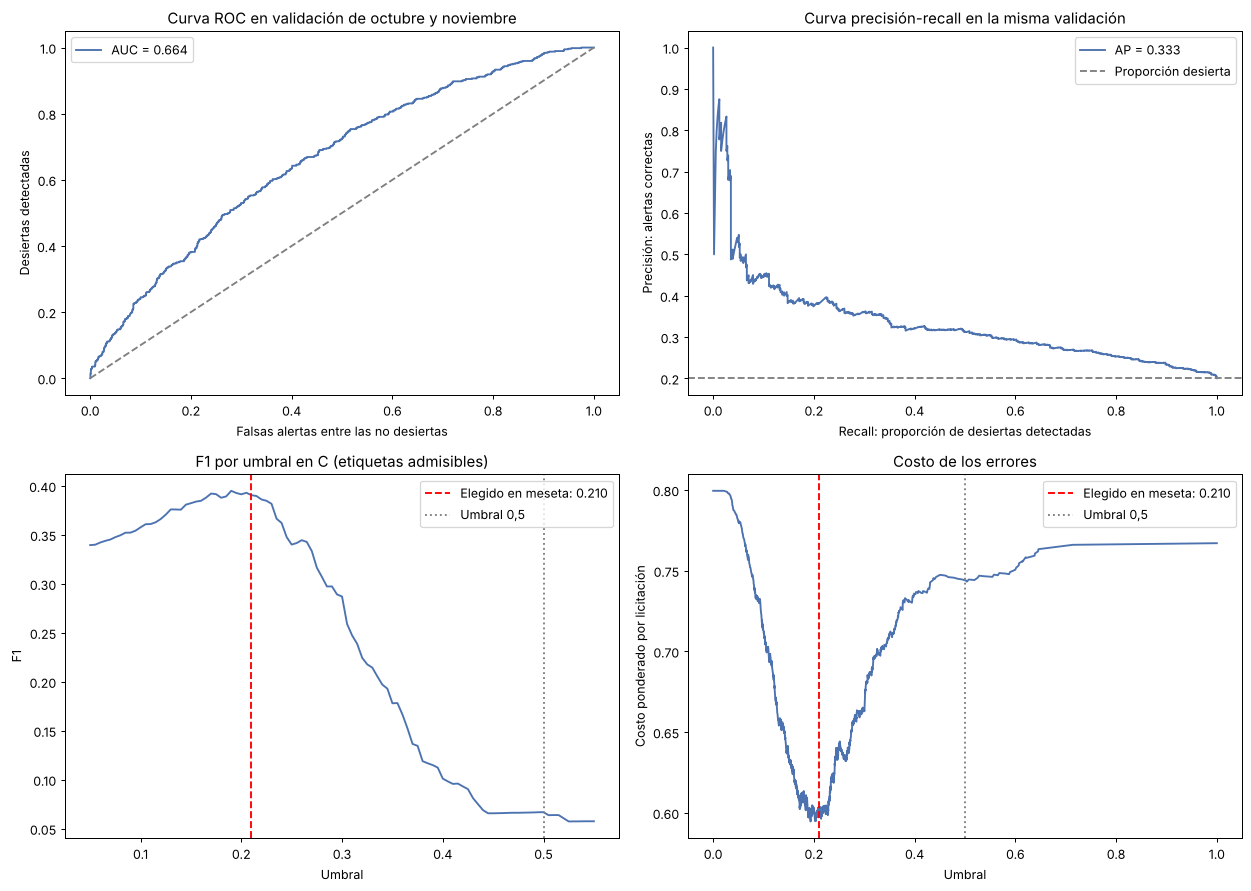

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
fpr, tpr, _ = roc_curve(y_val_umbral, proba_umbral)
ax[0, 0].plot(fpr, tpr, label=f"AUC = {metricas_umbral['roc_auc']:.3f}")
ax[0, 0].plot([0, 1], [0, 1], "--", color="gray")
ax[0, 0].set(xlabel="Falsas alertas entre las no desiertas", ylabel="Desiertas detectadas",
             title="Curva ROC en validación de octubre y noviembre")
ax[0, 0].legend()
precision_curva, recall_curva, _ = precision_recall_curve(y_val_umbral, proba_umbral)
ax[0, 1].plot(recall_curva, precision_curva, label=f"AP = {metricas_umbral['ap']:.3f}")
ax[0, 1].axhline(y_val_umbral.mean(), linestyle="--", color="gray", label="Proporción desierta")
ax[0, 1].set(xlabel="Recall: proporción de desiertas detectadas", ylabel="Precisión: alertas correctas",
             title="Curva precisión-recall en la misma validación")
ax[0, 1].legend()
ax[1, 0].plot(curva_umbral["threshold"], curva_umbral["f1"])
ax[1, 0].set(xlabel="Umbral", ylabel="F1", title="F1 por umbral en C (etiquetas admisibles)")
ax[1, 1].plot(curva_costos_umbral["threshold"], curva_costos_umbral["costo_por_licitacion"])
ax[1, 1].set(xlabel="Umbral", ylabel="Costo ponderado por licitación", title="Costo de los errores")
for panel in ax[1]:
    panel.axvline(mejor_threshold, color="red", linestyle="--", label=f"Elegido en meseta: {mejor_threshold:.3f}")
    panel.axvline(0.5, color="gray", linestyle=":", label="Umbral 0,5")
    panel.legend()
plt.tight_layout()

# 5. Árboles y ensambles

El árbol divide los datos mediante reglas. Limitar profundidad y exigir muchas observaciones por hoja reduce reglas demasiado específicas. Random Forest promedia árboles y restringe también qué variables considera cada división. El boosting construye árboles pequeños de forma secuencial, cada uno corrigiendo los errores del anterior.

Se recuperan las métricas iniciales de los tres en B con umbral 0,5. La elección ya se realizó con las tres ventanas; no se ajustan modelos nuevos aquí. Sus brechas entrenamiento-validación permiten compararlos con las regresiones regularizadas.

In [ ]:
comparacion_arbol_bosque = pd.DataFrame(resultados_base).loc[
    lambda t: t["modelo"].isin(["arbol_estructural", "bosque_estructural", "boosting_tasas"]),
    ["modelo", "ap_train", "ap", "brecha_ap", "f1", "precision", "recall", "costo_por_licitacion"]
]
display(comparacion_arbol_bosque.rename(columns=ETIQUETAS_RESULTADOS))

,Modelo,ap_train,Average Precision,brecha_ap,F1,Precisión,Recall,Costo por licitación
0,arbol_estructural,0.281486,0.253285,0.028201,0.061329,0.551020,0.032471,0.742302
1,bosque_estructural,0.340317,0.288747,0.051570,0.056128,0.590361,0.029465,0.743395
2,boosting_tasas,0.423787,0.344561,0.079226,0.099393,0.608108,0.054119,0.727488


# 6. Decisión final

La configuración y el uso del monto se eligieron con tres ventanas anteriores a octubre; el umbral se eligió con etiquetas de C admisibles antes del 15 de noviembre. Ahora se entrena únicamente con etiquetas admisibles antes de ese último corte y se evalúa todo D de forma retrospectiva.

Se reportan F1, precisión, recall, AP, ROC AUC, Brier y costos. Se comparan también las reglas triviales «ninguna desierta» y «todas desiertas». Un F1 apenas mayor que el de alertar en todos los casos constituye una mejora limitada. Los resultados de D no modifican configuración, variables, embargo ni umbral.

Se incluyen resultados por mes y un intervalo de F1 mediante remuestreo de semanas. Son diagnósticos de incertidumbre y variación temporal, no un permiso para retocar el modelo. D ya fue observado en versiones previas, y la fecha real de disponibilidad de las etiquetas sigue sin estar documentada.

In [ ]:
assert firma_configuracion == repr(mejor_modelo_config.get_params(deep=True))
modelo_evaluacion = ajustar_pipeline(clone(mejor_modelo_config), X_train_umbral, y_train_umbral, "ABC")
proba_test_temporal = modelo_evaluacion.predict_proba(X_test_temporal)[:, 1]
metricas_test_temporal = metricas_con_umbral(y_test_temporal, proba_test_temporal, mejor_threshold)
display(pd.Series(metricas_test_temporal).drop("matriz_confusion").rename(index=ETIQUETAS_RESULTADOS))
display(pd.DataFrame(metricas_test_temporal["matriz_confusion"],
    index=["real: no desierta", "real: desierta"], columns=["predicha: no desierta", "predicha: desierta"]))

comparacion_triviales = pd.DataFrame([
    {"regla": "Modelo fijado", **metricas_test_temporal},
    {"regla": "Nunca desierta", **metricas_con_umbral(y_test_temporal, np.zeros(len(y_test_temporal)), 0.5)},
    {"regla": "Siempre desierta", **metricas_con_umbral(y_test_temporal, np.ones(len(y_test_temporal)), 0.5)}
])
display(comparacion_triviales[["regla", "f1", "precision", "recall", "costo_por_licitacion"]])
diagnostico_mensual = pd.DataFrame([
    {"mes": mes, "n": len(grupo), **metricas_con_umbral(
        y_test_temporal.loc[grupo], proba_test_temporal[test_temporal.index.isin(grupo)], mejor_threshold)}
    for mes, grupo in test_temporal.groupby(test_temporal["pub_fecha"].dt.strftime("%Y-%m")).groups.items()
])
display(diagnostico_mensual[["mes", "n", "ap", "f1", "precision", "recall"]])

# Bootstrap por semanas: preserva agrupación temporal, sin reajustar decisiones.
semanas_d = test_temporal["pub_fecha"].dt.strftime("%Y-%W").to_numpy()
grupos_d = [np.flatnonzero(semanas_d == s) for s in np.unique(semanas_d)]
y_d = y_test_temporal.to_numpy()
pred_d = proba_test_temporal >= mejor_threshold
conteos_semanales = np.array([
    [np.sum(y_d[g] & pred_d[g]), np.sum((1-y_d[g]) & pred_d[g]), np.sum(y_d[g] & ~pred_d[g])]
    for g in grupos_d
])
rng = np.random.default_rng(SEED)
remuestreos = rng.integers(0, len(grupos_d), size=(1000, len(grupos_d)))
tp, fp, fn = conteos_semanales[remuestreos].sum(axis=1).T
f1_bootstrap = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
intervalo_f1_d = np.quantile(f1_bootstrap, [0.025, 0.975])
print("Intervalo percentil 95% de F1, bootstrap por semanas:", intervalo_f1_d)

Intervalo percentil 95% de F1, bootstrap por semanas: [0.37331992 0.4035503 ]


Umbral                                   0.21
F1                                   0.390212
Precisión                            0.288262
Recall                               0.603735
Average Precision                    0.350013
Área bajo ROC                        0.663069
Error de probabilidades (Brier)      0.150821
Proporción real desierta             0.202003
Proporción de alertas                0.423074
Falsas alertas                           4390
Desiertas no detectadas                  1167
Costo de falsas alertas                4390.0
Costo de casos no detectados       4464.70645
Costo total                        8854.70645
Costo por licitación                  0.60736

,predicha: no desierta,predicha: desierta
real: no desierta,7244,4390
real: desierta,1167,1778


,regla,f1,precision,recall,costo_por_licitacion
0,Modelo fijado,0.390212,0.288262,0.603735,0.607360
1,Nunca desierta,0.000000,0.000000,0.000000,0.772822
2,Siempre desierta,0.336110,0.202003,1.000000,0.797997


,mes,n,ap,f1,precision,recall
0,2024-11,7135,0.335692,0.382101,0.281902,0.592806
1,2024-12,7444,0.363833,0.397500,0.293991,0.613505


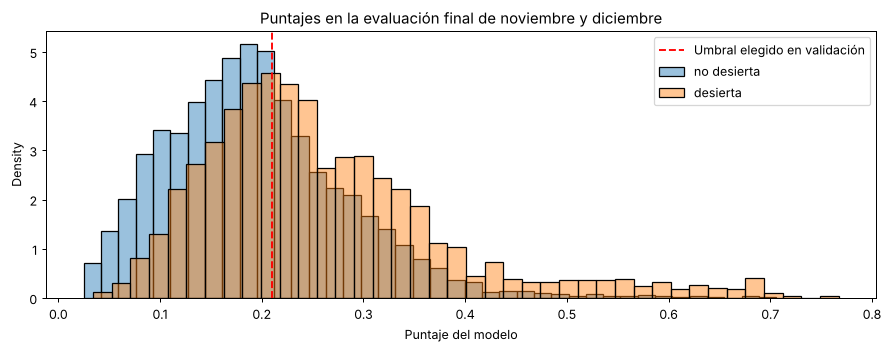

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for clase, color, etiqueta in ((0, "tab:blue", "no desierta"), (1, "tab:orange", "desierta")):
    sns.histplot(
        proba_test_temporal[y_test_temporal == clase], bins=40, stat="density",
        color=color, alpha=0.45, label=etiqueta, ax=ax
    )
ax.axvline(mejor_threshold, color="red", linestyle="--", label="Umbral elegido en validación")
ax.set(xlabel="Puntaje del modelo", title="Puntajes en la evaluación final de noviembre y diciembre")
ax.legend()
plt.tight_layout()


## Resumen y revisión de los datos

Los resultados corresponden a usos distintos: B participa en desarrollo, C elige el umbral y D describe el resultado posterior con decisiones cerradas. No son estimaciones intercambiables. B y C se restringen a etiquetas admisibles al tomar la decisión; D se evalúa completo ex post.

Después de cerrar las decisiones se describen faltantes y escalas en los bloques y en Kaggle, sin usar etiquetas de prueba ni adaptar el modelo a sus estadísticas. La comparación permite identificar desplazamientos, pero no medir el rendimiento de 2025.

In [ ]:
# Reutiliza el fit CV con A y validación en B; no usa el modelo AB que ya vio B.
modelo_resumen_b = modelos_cv_ajustados[(id_modelo_final_cv, "agosto_septiembre")]
metricas_b_cerrado = metricas_con_umbral(y_val_hparam, modelo_resumen_b.predict_proba(X_val_hparam)[:, 1], 0.5)
resumen_predicciones = pd.DataFrame([
    {"particion": "B (desarrollo, umbral 0.5)", "n": len(val_hparam), **metricas_b_cerrado},
    {"particion": "C (selección de umbral)", "n": len(val_umbral), **metricas_umbral},
    {"particion": "D (evaluación retrospectiva)", "n": len(test_temporal), **metricas_test_temporal}
])
display(resumen_predicciones[["particion", "n", "threshold", "ap", "f1", "precision", "recall",
    "falsos_positivos", "falsos_negativos", "costo_por_licitacion"]].rename(columns=ETIQUETAS_RESULTADOS))

# Ajuste final: etiquetas maduras antes del 1 de enero de 2025; los conteos usan todas las publicaciones de 2024.
X_2024, (test_features,) = construir_conjunto(train_final, [test_df], datos, FIN_2024)
datos_por_bloque = {**bloques, "E": test_df}
features_por_bloque = {
    "A": X_train_modelos, "B": X_val_hparam, "C": X_val_umbral, "D": X_test_temporal, "E": test_features
}
print("Porcentaje de nulos por columna de origen (bloques completos)")
display(pd.DataFrame({nombre: df[COLUMNAS_ORIGEN].isna().mean() * 100 for nombre, df in datos_por_bloque.items()}))
print("Medianas de features en las muestras usadas")
columnas_estabilidad = ["pub_dias_postulacion", "pub_dias_consultas", "log_monto_clp",
                        "log_titulo_largo", "log_descripcion_larga"]
display(pd.DataFrame({nombre: X[columnas_estabilidad].median() for nombre, X in features_por_bloque.items()}))
print("Montos por moneda: unidades separadas, solo diagnóstico")
display(pd.concat({
    nombre: df.groupby("pub_moneda", dropna=False)["pub_monto_estimado"].agg(["count", "median"])
    for nombre, df in datos_por_bloque.items()
}, names=["bloque", "moneda"]))

Porcentaje de nulos por columna de origen (bloques completos)
Medianas de features en las muestras usadas
Montos por moneda: unidades separadas, solo diagnóstico


,Bloque,Registros,Umbral,Average Precision,F1,Precisión,Recall,Falsas alertas,Desiertas no detectadas,Costo por licitación
0,"B (desarrollo, umbral 0.5)",8352,0.50,0.341195,0.089787,0.672269,0.048106,39,1583,0.729794
1,C (selección de umbral),2833,0.21,0.332601,0.390511,0.298327,0.565141,755,247,0.600061
2,D (evaluación retrospectiva),14579,0.21,0.350013,0.390212,0.288262,0.603735,4390,1167,0.607360


,A,B,C,D,E
pub_fecha,0.000000,0.000000,0.000000,0.000000,0.000000
pub_titulo,0.000000,0.000000,0.042238,0.000000,0.000000
pub_descripcion,0.000000,0.000000,0.042238,0.000000,0.000000
pub_monto_estimado,45.050823,41.813524,41.439835,46.031964,53.135737
pub_moneda,45.067324,41.848459,41.491459,46.038823,53.154061
pub_metodo,0.014301,0.065989,0.075089,0.150902,0.435201
pub_modalidad,0.000000,0.000000,0.000000,0.000000,0.000000
pub_n_items,0.000000,0.000000,0.000000,0.000000,0.000000
pub_cantidad_total,0.000000,0.000000,0.000000,0.000000,0.000000
pub_n_categorias,0.000000,0.000000,0.000000,0.000000,0.000000


,A,B,C,D,E
pub_dias_postulacion,9.900000,7.903000,6.993000,9.890000,10.257000
pub_dias_consultas,3.000000,3.000000,2.000000,3.000000,4.000000
log_monto_clp,15.687313,15.607270,15.468312,15.894952,17.005025
log_titulo_largo,3.891820,3.912023,3.912023,3.912023,3.891820
log_descripcion_larga,5.056246,5.030438,5.023881,5.093750,5.204007


count        median
bloque moneda                     
A      CLF       384  1.952750e+03
       CLP     49265  6.518000e+06
       EUR         1  2.500000e+07
       USD       286  3.345418e+04
       nan        15  5.000000e+02
B      CLF        93  2.100000e+03
       CLP     14798  6.500000e+06
       USD        90  3.157700e+04
       nan         9  3.500000e+03
C      CLF        83  2.614000e+03
       CLP     12294  6.500000e+06
       EUR         1  3.600000e+03
       USD        89  2.320000e+04
       nan        11  3.500000e+03
D      CLF        63  2.170000e+03
       CLP      7759  8.000000e+06
       USD        45  5.200000e+04
       nan         1  9.900000e+01
E      CLF       130  2.014060e+03
       CLP     10041  2.427600e+07
       USD        55  5.000000e+04
       nan         4  5.475000e+03

## Predicción y archivo para Kaggle

Se simula una predicción al comenzar 2025. El ajuste final usa únicamente etiquetas cuyo cierre + 30 días precede al 1 de enero de 2025; por eso no incluye automáticamente todas las etiquetas de 2024. Los conteos sí usan todas las publicaciones de 2024, sin sus desenlaces; las tasas históricas usan solo las etiquetas admisibles. El modelo, la inclusión del monto y el umbral permanecen fijados.

Se comprueban columnas, etiquetas binarias, tamaño, orden de identificadores y auditoría temporal antes de escribir `submission_pregunta2.csv`. También se guarda un JSON con configuraciones, versiones, resultados y huellas de las filas usadas para reproducir el procedimiento.

In [ ]:
y_2024 = train_final[TARGET].astype(int)
assert mejor_threshold == decisiones_cerradas["umbral"]
assert firma_configuracion == repr(mejor_modelo_config.get_params(deep=True))
modelo_final = ajustar_pipeline(clone(mejor_modelo_config), X_2024, y_2024, "ABCD")
proba_test = modelo_final.predict_proba(test_features)[:, 1]
assert np.isfinite(proba_test).all() and ((proba_test >= 0) & (proba_test <= 1)).all()
pred_test = (proba_test >= mejor_threshold).astype(int)

def crear_submission(predicciones, plantilla):
    assert plantilla["id"].equals(test_df["id"])
    resultado = pd.DataFrame({"id": test_df["id"], TARGET: predicciones})
    assert list(resultado.columns) == ["id", TARGET]
    assert len(resultado) == len(test_df) and resultado["id"].is_unique
    assert resultado["id"].equals(test_df["id"])
    assert resultado[TARGET].notna().all() and resultado[TARGET].isin([0, 1]).all()
    return resultado

submission = crear_submission(pred_test, sample_submission_df)
plantilla_alterada = sample_submission_df.assign(y_desierta=1 - pred_test)
pd.testing.assert_frame_equal(submission, crear_submission(pred_test, plantilla_alterada))
auditoria_ajustes = pd.DataFrame(registro_ajustes)
assert (auditoria_ajustes["hasta"] < auditoria_ajustes["limite"]).all()
assert (auditoria_ajustes["etiqueta_hasta_proxy"] < auditoria_ajustes["limite"]).all()
for v in ventanas_cv:
    assert etiquetas_admisibles(datos.loc[v["indices_val"]], CORTE_UMBRAL).all()
assert etiquetas_admisibles(val_umbral, CORTE_EVALUACION).all()
assert set(train_umbral["id"]).isdisjoint(test_temporal["id"])
assert set(train_final["id"]).isdisjoint(test_df["id"])
assert repr(mejor_modelo_config.get_params(deep=True)) == firma_configuracion

metricas_json = {k: v for k, v in metricas_test_temporal.items() if k != "matriz_confusion"}
reporte_validacion = {
    "versiones": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "semilla": SEED, "decisiones": decisiones_cerradas,
    "cv": tabla_resumen_cv.to_dict(orient="records"),
    "cv_por_ventana": resultados_cv, "ablacion_monto": tabla_monto_cv.to_dict(orient="records"),
    "aporte_monto_por_ventana": aporte_por_ventana.reset_index().to_dict(orient="records"),
    "diagnostico_complejidad_texto": comparacion_complejidad_texto.to_dict(orient="records"),
    "importancia_numerica_cv": tabla_importancia_numerica.reset_index().to_dict(orient="records"),
    "metricas_C": {k: v for k, v in metricas_umbral.items() if k != "matriz_confusion"},
    "metricas_D": metricas_json, "intervalo_f1_D_bootstrap_semanas": intervalo_f1_d.tolist(),
    "auditoria_ajustes": auditoria_ajustes.to_dict(orient="records"),
    "n_etiquetas_final": len(train_final), "n_predicciones": len(submission),
    "proporcion_predicha_2025": float(pred_test.mean()),
    "comprobaciones": ["lista blanca", "features independientes de y e id", "conteos solo pasado",
        "fit de preprocesamiento aislado", "cierre+embargo antes de cada fit y decisión",
        "placebo con etiquetas barajadas", "D fuera de selección", "plantilla sin uso de etiquetas", "IDs y orden de entrega"],
    "limitaciones": ["Disponibilidad real de etiquetas desconocida; se aproxima con cierre+30 días.",
        "D ya observado en versiones previas; no es una nueva evaluación independiente.",
        "Ablación y búsqueda reutilizan desarrollo; no demuestran significancia ni rendimiento en 2025."]
}
Path("validacion_pregunta2.json").write_text(
    json.dumps(reporte_validacion, ensure_ascii=False, indent=2, default=str) + "\n", encoding="utf-8"
)
submission.to_csv("submission_pregunta2.csv", index=False)
display(auditoria_ajustes.groupby("etapa", sort=False).agg(
    ajustes=("n", "size"), registros=("n", "first"), hasta=("hasta", "max"),
    etiqueta_hasta_proxy=("etiqueta_hasta_proxy", "max"), limite=("limite", "first")
))
display(pd.Series({"proporcion_predicha_2025": pred_test.mean(), "probabilidad_media_2025": proba_test.mean(),
    "probabilidad_p10": np.quantile(proba_test, 0.1), "probabilidad_mediana": np.median(proba_test),
    "probabilidad_p90": np.quantile(proba_test, 0.9)}))

,ajustes,registros,hasta,etiqueta_hasta_proxy,limite
etapa,,,,,
A,6,67566,2024-06-27 07:54:42+00:00,2024-07-31 23:55:00+00:00,2024-08-01 00:00:00+00:00
CV_junio,16,42017,2024-04-26 09:42:48+00:00,2024-05-30 23:59:00+00:00,2024-06-01 00:00:00+00:00
CV_julio,16,54499,2024-05-29 17:46:36+00:00,2024-06-30 21:50:00+00:00,2024-07-01 00:00:00+00:00
CV_agosto_septiembre,16,67566,2024-06-27 07:54:42+00:00,2024-07-31 23:55:00+00:00,2024-08-01 00:00:00+00:00
AB,1,92602,2024-08-27 17:33:18+00:00,2024-09-29 20:25:00+00:00,2024-10-01 00:00:00+00:00
ABC,1,110740,2024-10-14 15:17:44+00:00,2024-11-14 23:00:00+00:00,2024-11-15 00:00:00+00:00
ABCD,1,130325,2024-11-28 10:18:19+00:00,2024-12-29 23:59:00+00:00,2025-01-01 00:00:00+00:00


proporcion_predicha_2025    0.442622
probabilidad_media_2025     0.212331
probabilidad_p10            0.089466
probabilidad_mediana        0.197791
probabilidad_p90            0.345400

In [ ]:
submission.head()

Después de ejecutar todo el notebook, `submission_pregunta2.csv` contiene las predicciones y `validacion_pregunta2.json` conserva el registro del procedimiento. `validar_pregunta2.py` permite repetir la ejecución y guardar las salidas sin depender de Jupyter.

La protección frente a fuga comprobable incluye lista blanca de predictores, ajuste del preprocesamiento solo con entrenamiento, conteos sin etiquetas y estrictamente pasados, tasas históricas con etiquetas maduras (recalculadas de forma independiente en las pruebas), exclusión de etiquetas no maduras bajo la aproximación declarada y separación de selección, umbral y evaluación. Las comprobaciones no certifican la fecha real en que se publicó cada resultado ni revierten que D ya se hubiera observado. Para esa garantía se necesitan metadatos de disponibilidad y un período futuro sin consultar. La proporción de alertas de Kaggle no mide su calidad; sin sus etiquetas no puede afirmarse una mejora en 2025.